In [1]:
# ============================================================
# CELL 1: Import Libraries & Setup Environment
# ============================================================

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pickle
import json
import os
import warnings
warnings.filterwarnings('ignore')

# Set style visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.family'] = 'DejaVu Sans'

# Buat folder output Flask
folders = [
    'flask_app/static/models',
    'flask_app/static/data',
    'flask_app/static/images/charts',
    'static/images/maps'
]
for folder in folders:
    os.makedirs(folder, exist_ok=True)

# Konstanta
KOMODITAS_LIST  = ['Karet', 'Kelapa', 'Pinang']
YEARS           = [2020, 2021, 2022, 2023, 2024]
N_CLUSTERS      = 3
CLUSTER_NAMES   = {1: 'Rendah', 2: 'Sedang', 3: 'Tinggi'}
CLUSTER_COLORS  = {1: '#4CAF50', 2: '#FF9800', 3: '#F44336'}
CLUSTER_COLORS_MAP = {
    'Rendah': '#4CAF50',
    'Sedang': '#FF9800',
    'Tinggi': '#F44336'
}

# Variabel clustering
CLUSTERING_VARS = ['Produksi_Ton', 'Produktivitas_KgHa']

print('✅ Setup environment selesai')
print('✅ Semua library berhasil diimport')
print(f'\nKomoditas : {KOMODITAS_LIST}')
print(f'Tahun     : {YEARS}')
print(f'Cluster   : {N_CLUSTERS} (Rendah, Sedang, Tinggi)')
print(f'Variabel  : {CLUSTERING_VARS}')
print(f'\nFolder yang dibuat:')
for f in folders:
    print(f'  📁 {f}')

✅ Setup environment selesai
✅ Semua library berhasil diimport

Komoditas : ['Karet', 'Kelapa', 'Pinang']
Tahun     : [2020, 2021, 2022, 2023, 2024]
Cluster   : 3 (Rendah, Sedang, Tinggi)
Variabel  : ['Produksi_Ton', 'Produktivitas_KgHa']

Folder yang dibuat:
  📁 flask_app/static/models
  📁 flask_app/static/data
  📁 flask_app/static/images/charts
  📁 static/images/maps


In [2]:
# ============================================================
# CELL 2: Load, Cleaning & Eksplorasi Dataset
# ============================================================

# Sumber: DATA DONE.xlsx — satu tabel per komoditas, tiap tahun
# berjejer ke samping (TAHUN | KECAMATAN | PRODUKTIVITAS | PRODUKSI | KOMODITAS)
# dan diakhiri baris total.
raw = pd.read_excel('DATA DONE.xlsx', header=None)

records = []
for r in range(raw.shape[0]):
    for c in range(raw.shape[1]):
        if str(raw.iat[r, c]).strip().upper() != 'TAHUN':
            continue
        # Baca baris di bawah header sampai kolom TAHUN kosong (baris total)
        i = r + 1
        while i < raw.shape[0] and pd.notna(raw.iat[i, c]):
            records.append({
                'Komoditas'         : raw.iat[i, c + 4],
                'Tahun'             : raw.iat[i, c],
                'Kecamatan'         : raw.iat[i, c + 1],
                'Produksi_Ton'      : raw.iat[i, c + 3],
                'Produktivitas_KgHa': raw.iat[i, c + 2],
            })
            i += 1

df = pd.DataFrame(records)

# Data cleaning: seragamkan penulisan nama & ubah nilai teks menjadi angka
df['Komoditas']          = df['Komoditas'].str.strip().str.title()
df['Kecamatan']          = df['Kecamatan'].str.strip().str.title()
df['Tahun']              = df['Tahun'].astype(int)
df['Produksi_Ton']       = pd.to_numeric(df['Produksi_Ton'], errors='coerce')
df['Produktivitas_KgHa'] = pd.to_numeric(df['Produktivitas_KgHa'], errors='coerce')
df = df.sort_values(['Komoditas', 'Tahun']).reset_index(drop=True)

print('INFORMASI DATASET')
print('=' * 55)
print(f'Jumlah baris    : {len(df)}')
print(f'Jumlah kolom    : {len(df.columns)}')
print(f'Kolom           : {list(df.columns)}')
print(f'Komoditas       : {df["Komoditas"].unique().tolist()}')
print(f'Tahun           : {sorted(df["Tahun"].unique().tolist())}')
print(f'Jumlah kecamatan: {df["Kecamatan"].nunique()}')

# Cek missing values
print('\nCEK MISSING VALUES')
print('-' * 30)
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else '✅ Tidak ada missing values')

# Preview
print('\nPREVIEW DATASET')
print('-' * 30)
display(df.head(10))

# Statistik deskriptif per komoditas
print('\nSTATISTIK DESKRIPTIF PRODUKSI PER KOMODITAS (Ton)')
print('-' * 50)
stats = df.groupby('Komoditas')['Produksi_Ton'].describe().round(4)
display(stats)

# Simpan dataset bersih
df.to_csv('perkebunan_bireuen.csv', index=False)
df.to_csv('flask_app/static/data/perkebunan_bireuen_original.csv', index=False)
print('\n✅ Dataset berhasil dimuat, dibersihkan, dan disimpan ke Flask')


INFORMASI DATASET
Jumlah baris    : 255
Jumlah kolom    : 5
Kolom           : ['Komoditas', 'Tahun', 'Kecamatan', 'Produksi_Ton', 'Produktivitas_KgHa']
Komoditas       : ['Karet', 'Kelapa', 'Pinang']
Tahun           : [2020, 2021, 2022, 2023, 2024]
Jumlah kecamatan: 17

CEK MISSING VALUES
------------------------------
✅ Tidak ada missing values

PREVIEW DATASET
------------------------------


,Komoditas,Tahun,Kecamatan,Produksi_Ton,Produktivitas_KgHa
0,Karet,2020,Samalanga,61.5,900.0
1,Karet,2020,Simpang Mamplam,392.2,920.0
2,Karet,2020,Pandrah,54.3,900.0
3,Karet,2020,Jeunieb,123.5,900.0
4,Karet,2020,Peulimbang,69.6,890.0
5,Karet,2020,Peudada,79.0,875.0
6,Karet,2020,Juli,313.1,890.0
7,Karet,2020,Jeumpa,108.3,900.0
8,Karet,2020,Kota Juang,20.5,790.0
9,Karet,2020,Kuala,50.1,810.0



STATISTIK DESKRIPTIF PRODUKSI PER KOMODITAS (Ton)
--------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Komoditas,,,,,,,,
Karet,85.0,159.0609,148.7138,1.31,61.5,105.02,230.99,682.46
Kelapa,85.0,1028.4828,843.9633,87.32,219.7,758.67,1747.50,2729.24
Pinang,85.0,335.8206,537.3354,3.65,87.4,117.00,379.68,2422.50



✅ Dataset berhasil dimuat, dibersihkan, dan disimpan ke Flask


INFORMASI SHAPEFILE
Jumlah baris (desa) : 613
CRS                 : None
Kolom utama         : KECAMATAN, geometry
✅ CRS diset ke WGS84 (EPSG:4326)

Jumlah kecamatan di SHP: 17
Nama kecamatan di SHP:
['GANDAPURA', 'JANGKA', 'JEUMPA', 'JEUNIEB', 'JULI', 'KOTA JUANG', 'KUALA', 'KUTA BLANG', 'MAKMUR', 'PANDRAH', 'PEUDADA', 'PEULIMBANG', 'PEUSANGAN', 'PEUSANGAN SELATAN', 'PEUSANGAN SIBLAH KRUENG', 'SAMALANGA', 'SIMPANG MAMPLAM']

✅ Semua kecamatan berhasil di-mapping

Hasil mapping:


,KECAMATAN,Kecamatan
0,GANDAPURA,Gandapura
1,JANGKA,Jangka
2,JEUMPA,Jeumpa
3,JEUNIEB,Jeunieb
4,JULI,Juli
5,KOTA JUANG,Kota Juang
6,KUALA,Kuala
7,KUTA BLANG,Kutablang
8,MAKMUR,Makmur
9,PANDRAH,Pandrah


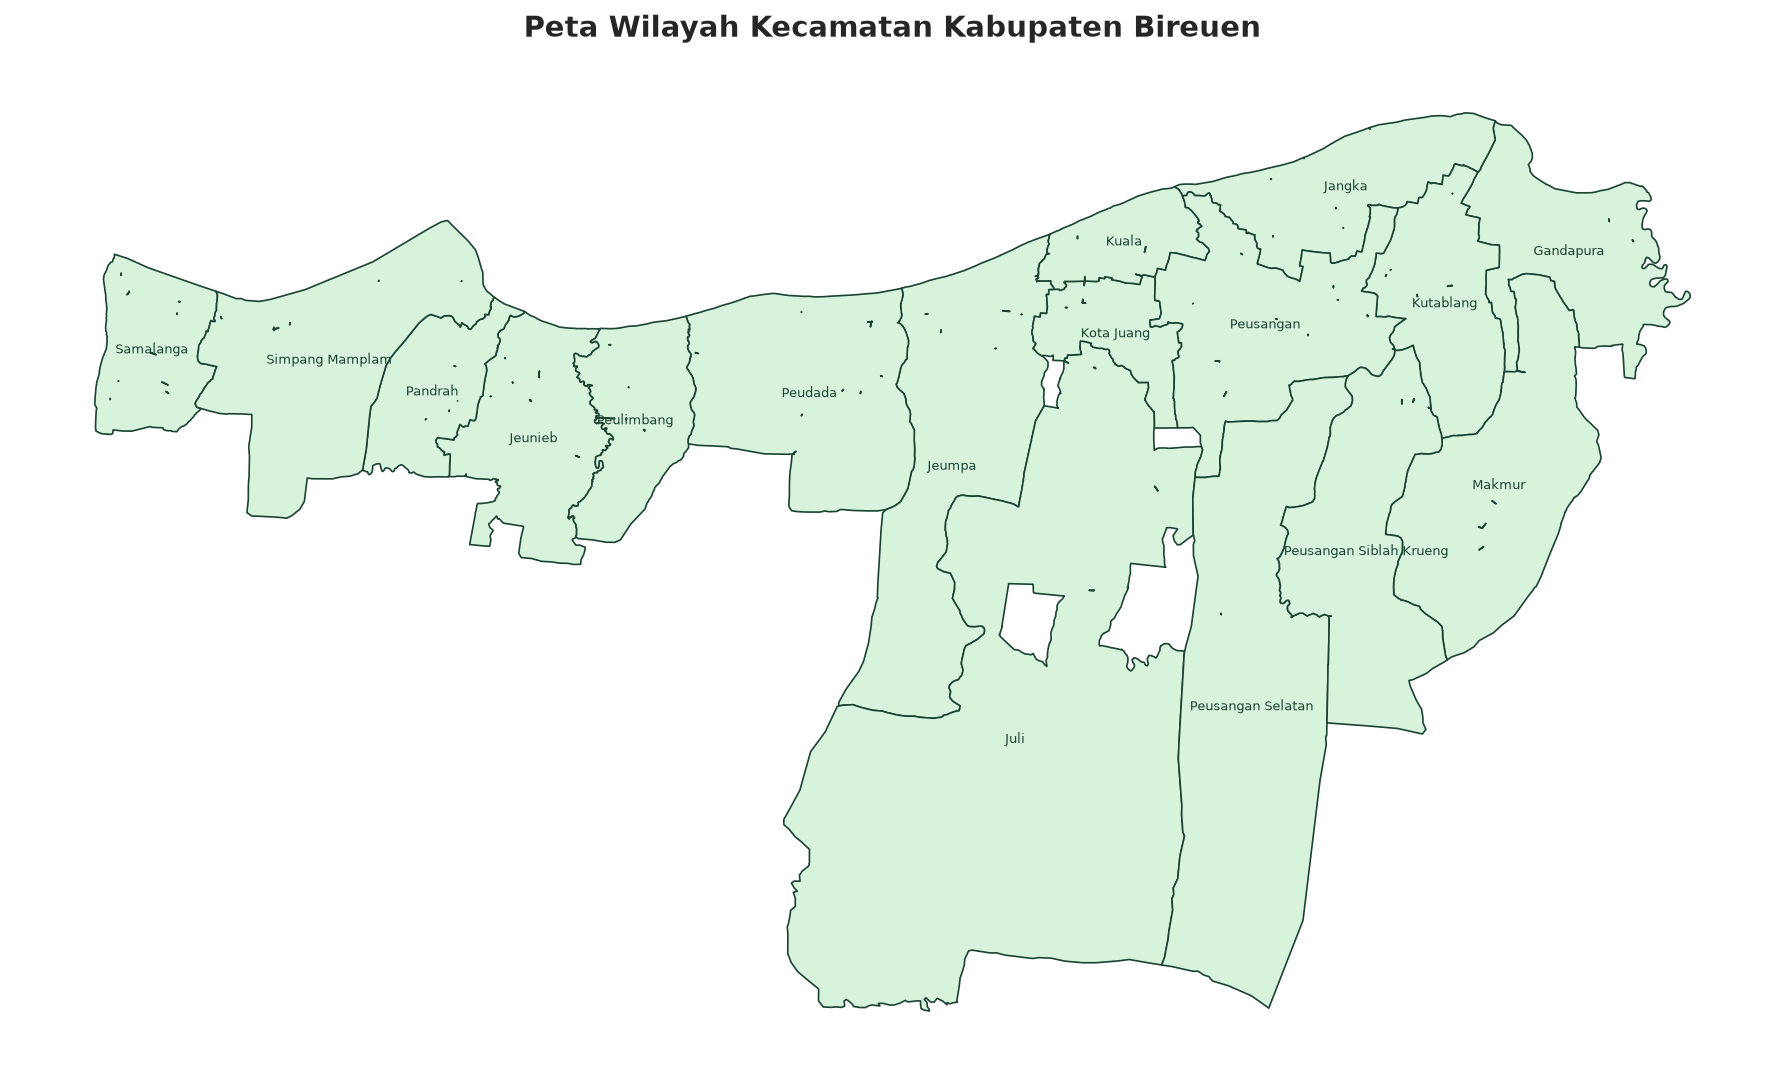

✅ Shapefile berhasil diproses dan peta dasar disimpan


In [3]:
# ============================================================
# CELL 3: Load & Preprocessing Shapefile Bireuen
# ============================================================

# Load shapefile
shp_path = 'Bireuen.shp'
gdf_desa = gpd.read_file(shp_path)

print('INFORMASI SHAPEFILE')
print('=' * 55)
print(f'Jumlah baris (desa) : {len(gdf_desa)}')
print(f'CRS                 : {gdf_desa.crs}')
print(f'Kolom utama         : KECAMATAN, geometry')

# Set CRS ke WGS84 jika belum ada
if gdf_desa.crs is None:
    gdf_desa = gdf_desa.set_crs('EPSG:4326')
    print('✅ CRS diset ke WGS84 (EPSG:4326)')

# Dissolve ke level kecamatan
gdf_kec = gdf_desa.dissolve(by='KECAMATAN').reset_index()
gdf_kec = gdf_kec[['KECAMATAN', 'geometry']].copy()

print(f'\nJumlah kecamatan di SHP: {len(gdf_kec)}')
print('Nama kecamatan di SHP:')
print(sorted(gdf_kec['KECAMATAN'].tolist()))

# Mapping nama kecamatan SHP → dataset
kec_mapping = {
    'SAMALANGA'              : 'Samalanga',
    'SIMPANG MAMPLAM'        : 'Simpang Mamplam',
    'PANDRAH'                : 'Pandrah',
    'JEUNIEB'                : 'Jeunieb',
    'PEULIMBANG'             : 'Peulimbang',
    'PEUDADA'                : 'Peudada',
    'JULI'                   : 'Juli',
    'JEUMPA'                 : 'Jeumpa',
    'KOTA JUANG'             : 'Kota Juang',
    'KUALA'                  : 'Kuala',
    'JANGKA'                 : 'Jangka',
    'PEUSANGAN'              : 'Peusangan',
    'PEUSANGAN SELATAN'      : 'Peusangan Selatan',
    'PEUSANGAN SIBLAH KRUENG': 'Peusangan Siblah Krueng',
    'MAKMUR'                 : 'Makmur',
    'GANDAPURA'              : 'Gandapura',
    'KUTA BLANG'             : 'Kutablang',
}

# Terapkan mapping
gdf_kec['Kecamatan'] = gdf_kec['KECAMATAN'].map(kec_mapping)

# Cek kecamatan yang tidak ter-mapping
unmapped = gdf_kec[gdf_kec['Kecamatan'].isna()]['KECAMATAN'].tolist()
if unmapped:
    print(f'\n⚠️ Kecamatan tidak ter-mapping: {unmapped}')
else:
    print('\n✅ Semua kecamatan berhasil di-mapping')

print('\nHasil mapping:')
display(gdf_kec[['KECAMATAN', 'Kecamatan']].head(20))

# Plot peta dasar
fig, ax = plt.subplots(figsize=(12, 8))
gdf_kec.plot(
    color='#D8F3DC',
    edgecolor='#1B4332',
    linewidth=0.8,
    ax=ax
)

# Label kecamatan
for idx, row in gdf_kec.iterrows():
    if row.geometry and row['Kecamatan']:
        ax.annotate(
            text=row['Kecamatan'],
            xy=(row.geometry.centroid.x, row.geometry.centroid.y),
            fontsize=6,
            ha='center',
            va='center',
            color='#1B4332'
        )

ax.set_title('Peta Wilayah Kecamatan Kabupaten Bireuen',
             fontsize=14, fontweight='bold', pad=15)
ax.set_axis_off()
plt.tight_layout()
plt.savefig('static/images/maps/peta_dasar.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('✅ Shapefile berhasil diproses dan peta dasar disimpan')

In [4]:
# ============================================================
# CELL 4: Implementasi Fungsi K-Means Clustering
# ============================================================

def kmeans_clustering(df_input, komoditas, tahun, vars_cluster=CLUSTERING_VARS):
    """
    Jalankan K-Means Clustering untuk komoditas dan tahun tertentu.

    Parameter:
        df_input    : DataFrame lengkap
        komoditas   : 'Karet' | 'Kelapa' | 'Pinang'
        tahun       : 2020 | 2021 | 2022 | 2023 | 2024
        vars_cluster: list variabel yang digunakan

    Return:
        dict hasil clustering lengkap
    """
    # Filter data: komoditas + tahun
    df_filtered = df_input[
        (df_input['Komoditas'] == komoditas) &
        (df_input['Tahun']     == tahun)
    ].copy().reset_index(drop=True)

    # Tangani missing values
    for col in vars_cluster:
        if col in df_filtered.columns:
            df_filtered[col] = df_filtered[col].fillna(df_filtered[col].mean())

    # Ambil variabel clustering
    X_raw = df_filtered[vars_cluster].values

    # Normalisasi Min-Max
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X_raw)

    # K-Means
    kmeans = KMeans(
        n_clusters=N_CLUSTERS,
        max_iter=300,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)

    # Hitung jarak ke centroid
    distances = kmeans.transform(X_scaled)

    # Evaluasi
    sil_score = silhouette_score(X_scaled, labels)
    dbi_score = davies_bouldin_score(X_scaled, labels)

    # Mapping cluster ke kategori (Rendah=1, Sedang=2, Tinggi=3)
    # Berdasarkan rata-rata Produksi_Ton per cluster
    prod_idx = vars_cluster.index('Produksi_Ton')
    cluster_prod_mean = {}
    for c in range(N_CLUSTERS):
        mask = labels == c
        cluster_prod_mean[c] = X_raw[mask, prod_idx].mean()

    # Urutkan cluster berdasarkan rata-rata produksi
    sorted_clusters = sorted(cluster_prod_mean.items(), key=lambda x: x[1])
    cluster_mapping = {
        sorted_clusters[0][0]: 1,  # Rendah
        sorted_clusters[1][0]: 2,  # Sedang
        sorted_clusters[2][0]: 3   # Tinggi
    }

    # Terapkan mapping
    mapped_labels   = [cluster_mapping[l] for l in labels]
    df_filtered['Cluster']       = mapped_labels
    df_filtered['Cluster_Nama']  = [CLUSTER_NAMES[l] for l in mapped_labels]
    df_filtered['Cluster_Warna'] = [CLUSTER_COLORS[l] for l in mapped_labels]

    # Centroid ke nilai asli
    original_centroids = scaler.inverse_transform(kmeans.cluster_centers_)

    # Iterasi konvergensi
    n_iter = kmeans.n_iter_

    return {
        'komoditas'          : komoditas,
        'tahun'              : tahun,
        'kecamatan'          : df_filtered['Kecamatan'].tolist(),
        'data_asli'          : df_filtered[vars_cluster].to_dict(orient='records'),
        'data_scaled'        : X_scaled.tolist(),
        'labels_raw'         : labels.tolist(),
        'labels_mapped'      : mapped_labels,
        'cluster_nama'       : df_filtered['Cluster_Nama'].tolist(),
        'centroids_scaled'   : kmeans.cluster_centers_.tolist(),
        'centroids_asli'     : original_centroids.tolist(),
        'distances'          : distances.tolist(),
        'cluster_mapping'    : {int(k): int(v) for k, v in cluster_mapping.items()},
        'silhouette_score'   : round(float(sil_score), 4),
        'dbi_score'          : round(float(dbi_score), 4),
        'inertia'            : round(float(kmeans.inertia_), 4),
        'n_iter'             : int(n_iter),
        'vars_cluster'       : vars_cluster,
        'df_result'          : df_filtered,
        'scaler'             : scaler,
        'kmeans_model'       : kmeans
    }


def get_cluster_summary(result):
    """Ringkasan distribusi cluster dari hasil clustering"""
    dist = {1: 0, 2: 0, 3: 0}
    for l in result['labels_mapped']:
        dist[l] += 1
    return dist


print('✅ Fungsi K-Means Clustering berhasil dibuat')
print('✅ Fungsi evaluasi Silhouette Score & DBI berhasil dibuat')
print('✅ Fungsi mapping cluster (Rendah/Sedang/Tinggi) berhasil dibuat')

✅ Fungsi K-Means Clustering berhasil dibuat
✅ Fungsi evaluasi Silhouette Score & DBI berhasil dibuat
✅ Fungsi mapping cluster (Rendah/Sedang/Tinggi) berhasil dibuat


In [5]:
# ============================================================
# CELL 5: Proses K-Means untuk Semua Komoditas & Tahun
# ============================================================

print('PROSES K-MEANS CLUSTERING — SEMUA KOMODITAS & TAHUN')
print('=' * 55)

# Dictionary untuk menyimpan semua hasil
all_results = {}

for komoditas in KOMODITAS_LIST:
    all_results[komoditas] = {}
    print(f'\n{"="*55}')
    print(f'  KOMODITAS: {komoditas.upper()}')
    print(f'{"="*55}')

    for tahun in YEARS:
        result = kmeans_clustering(df, komoditas, tahun)
        all_results[komoditas][tahun] = result

        dist = get_cluster_summary(result)

        print(f'\n  Tahun {tahun}:')
        print(f'    Silhouette Score : {result["silhouette_score"]}')
        print(f'    DBI Score        : {result["dbi_score"]}')
        print(f'    Iterasi          : {result["n_iter"]}')
        print(f'    Inertia          : {result["inertia"]}')
        print(f'    Distribusi       : '
              f'Rendah={dist[1]} | '
              f'Sedang={dist[2]} | '
              f'Tinggi={dist[3]}')

        # Tampilkan hasil per kecamatan
        df_res = result['df_result'][
            ['Kecamatan', 'Produksi_Ton', 'Produktivitas_KgHa',
             'Cluster', 'Cluster_Nama']
        ].sort_values('Cluster')
        display(df_res)

print(f'\n{"="*55}')
print(f'✅ Selesai: {len(KOMODITAS_LIST)} komoditas × {len(YEARS)} tahun'
      f' = {len(KOMODITAS_LIST)*len(YEARS)} hasil clustering')

PROSES K-MEANS CLUSTERING — SEMUA KOMODITAS & TAHUN

  KOMODITAS: KARET

  Tahun 2020:
    Silhouette Score : 0.6693
    DBI Score        : 0.4389
    Iterasi          : 6
    Inertia          : 0.3178
    Distribusi       : Rendah=2 | Sedang=13 | Tinggi=2


,Kecamatan,Produksi_Ton,Produktivitas_KgHa,Cluster,Cluster_Nama
16,Kutablang,34.6,400.0,1,Rendah
10,Jangka,8.1,630.0,1,Rendah
14,Makmur,67.8,780.0,2,Sedang
13,Peusangan Siblah Krueng,98.8,950.0,2,Sedang
12,Peusangan Selatan,120.4,890.0,2,Sedang
11,Peusangan,29.8,870.0,2,Sedang
9,Kuala,50.1,810.0,2,Sedang
15,Gandapura,67.9,780.0,2,Sedang
0,Samalanga,61.5,900.0,2,Sedang
5,Peudada,79.0,875.0,2,Sedang



  Tahun 2021:
    Silhouette Score : 0.6283
    DBI Score        : 0.4558
    Iterasi          : 3
    Inertia          : 0.3616
    Distribusi       : Rendah=2 | Sedang=12 | Tinggi=3


,Kecamatan,Produksi_Ton,Produktivitas_KgHa,Cluster,Cluster_Nama
16,Kutablang,35.76,435.0,1,Rendah
10,Jangka,12.34,600.0,1,Rendah
14,Makmur,96.87,770.0,2,Sedang
12,Peusangan Selatan,130.50,900.0,2,Sedang
11,Peusangan,67.87,910.0,2,Sedang
9,Kuala,75.67,780.0,2,Sedang
15,Gandapura,45.67,765.0,2,Sedang
0,Samalanga,78.76,895.0,2,Sedang
5,Peudada,105.02,890.0,2,Sedang
4,Peulimbang,105.91,890.0,2,Sedang



  Tahun 2022:
    Silhouette Score : 0.5133
    DBI Score        : 0.5748
    Iterasi          : 2
    Inertia          : 0.4641
    Distribusi       : Rendah=2 | Sedang=12 | Tinggi=3


...


  Tahun 2023:
    Silhouette Score : 0.7155
    DBI Score        : 0.2195
    Iterasi          : 2
    Inertia          : 0.2411
    Distribusi       : Rendah=12 | Sedang=4 | Tinggi=1


,Kecamatan,Produksi_Ton,Produktivitas_KgHa,Cluster,Cluster_Nama
0,Samalanga,192.30,760.0,1,Rendah
11,Peusangan,172.50,750.0,1,Rendah
10,Jangka,126.92,760.0,1,Rendah
9,Kuala,5.11,730.0,1,Rendah
15,Gandapura,93.75,750.0,1,Rendah
8,Kota Juang,42.92,740.0,1,Rendah
4,Peulimbang,103.50,750.0,1,Rendah
3,Jeunieb,172.50,750.0,1,Rendah
2,Pandrah,82.39,770.0,1,Rendah
1,Simpang Mamplam,106.10,780.0,1,Rendah



  Tahun 2024:
    Silhouette Score : 0.7389
    DBI Score        : 0.1876
    Iterasi          : 3
    Inertia          : 0.1571
    Distribusi       : Rendah=12 | Sedang=4 | Tinggi=1


,Kecamatan,Produksi_Ton,Produktivitas_KgHa,Cluster,Cluster_Nama
0,Samalanga,180.48,752.0,1,Rendah
11,Peusangan,162.75,775.0,1,Rendah
10,Jangka,97.28,760.0,1,Rendah
9,Kuala,5.11,730.0,1,Rendah
15,Gandapura,78.75,750.0,1,Rendah
8,Kota Juang,37.00,740.0,1,Rendah
4,Peulimbang,98.15,755.0,1,Rendah
3,Jeunieb,152.25,750.0,1,Rendah
2,Pandrah,79.50,750.0,1,Rendah
1,Simpang Mamplam,102.60,760.0,1,Rendah



✅ Selesai: 3 komoditas × 5 tahun = 15 hasil clustering


VISUALISASI PETA CLUSTER

📍 PETA CLUSTER — KARET


  ✅ Disimpan → static/images/maps/peta_karet_2020.png


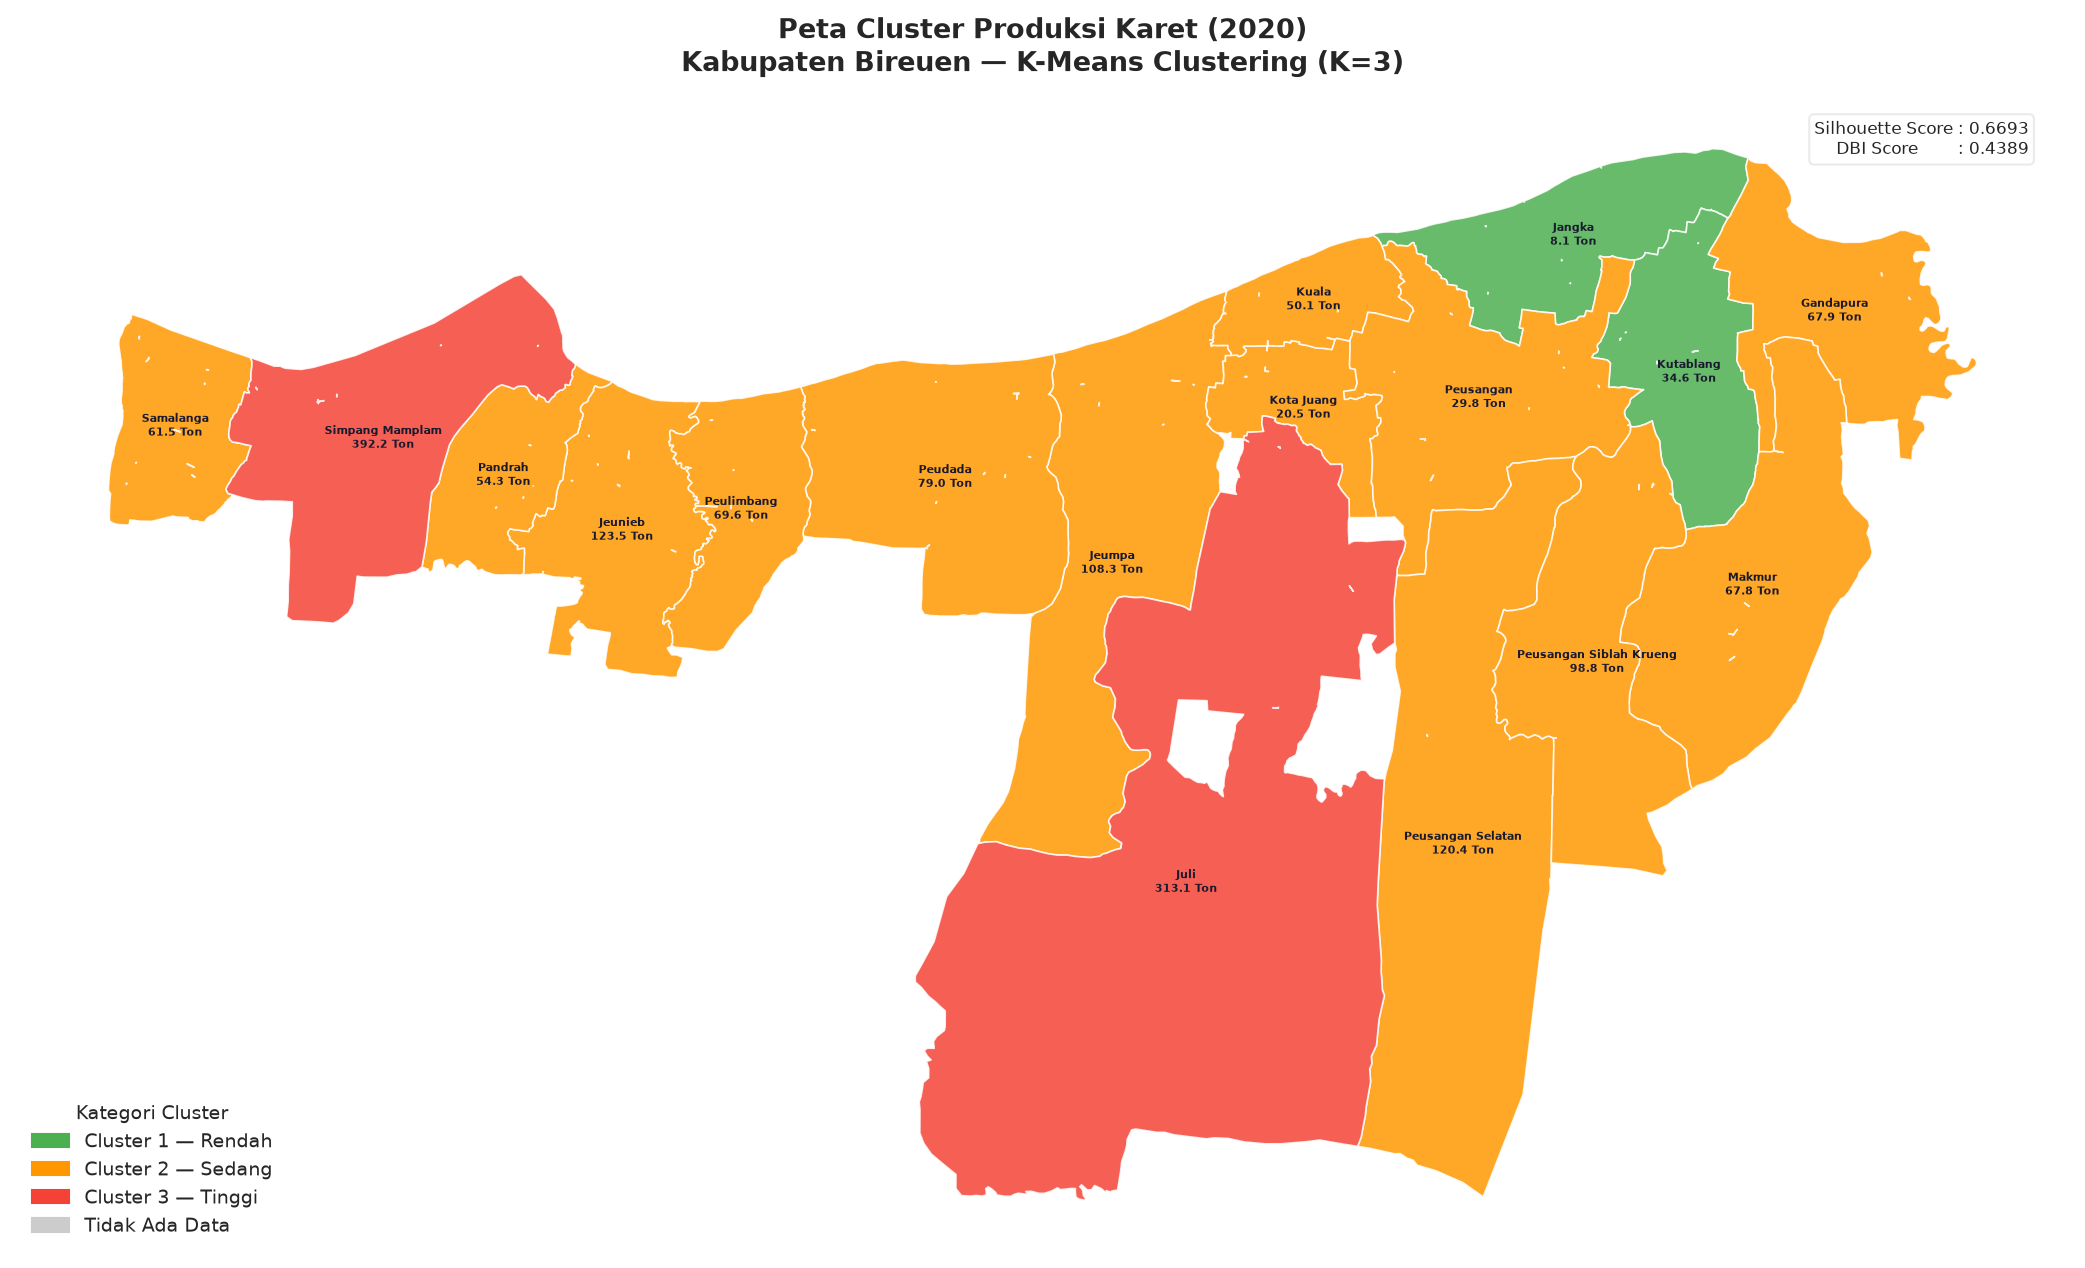

  ✅ Disimpan → static/images/maps/peta_karet_2021.png


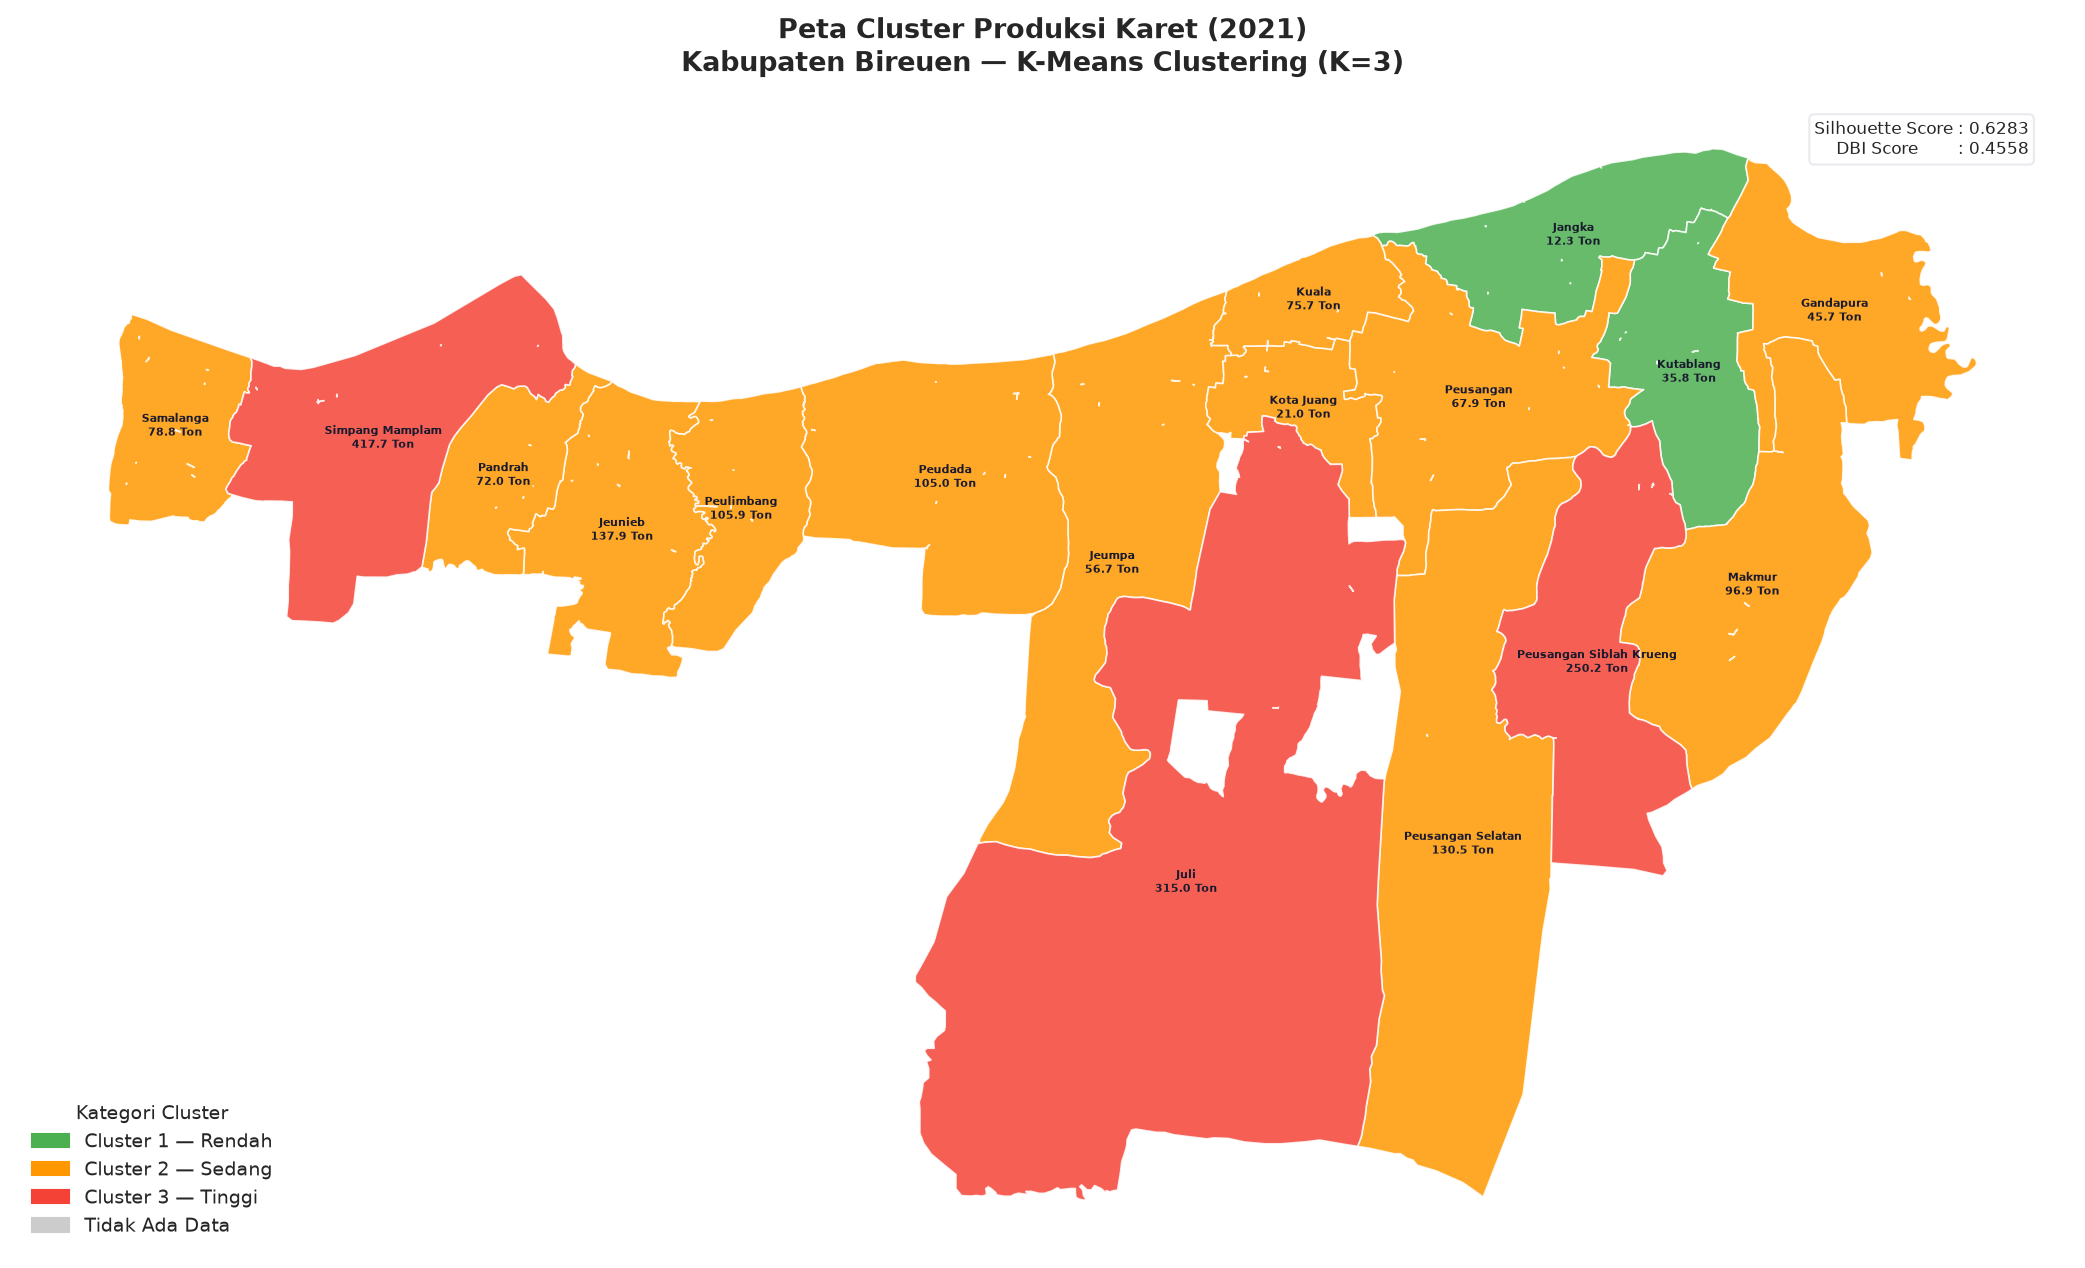

  ✅ Disimpan → static/images/maps/peta_karet_2022.png


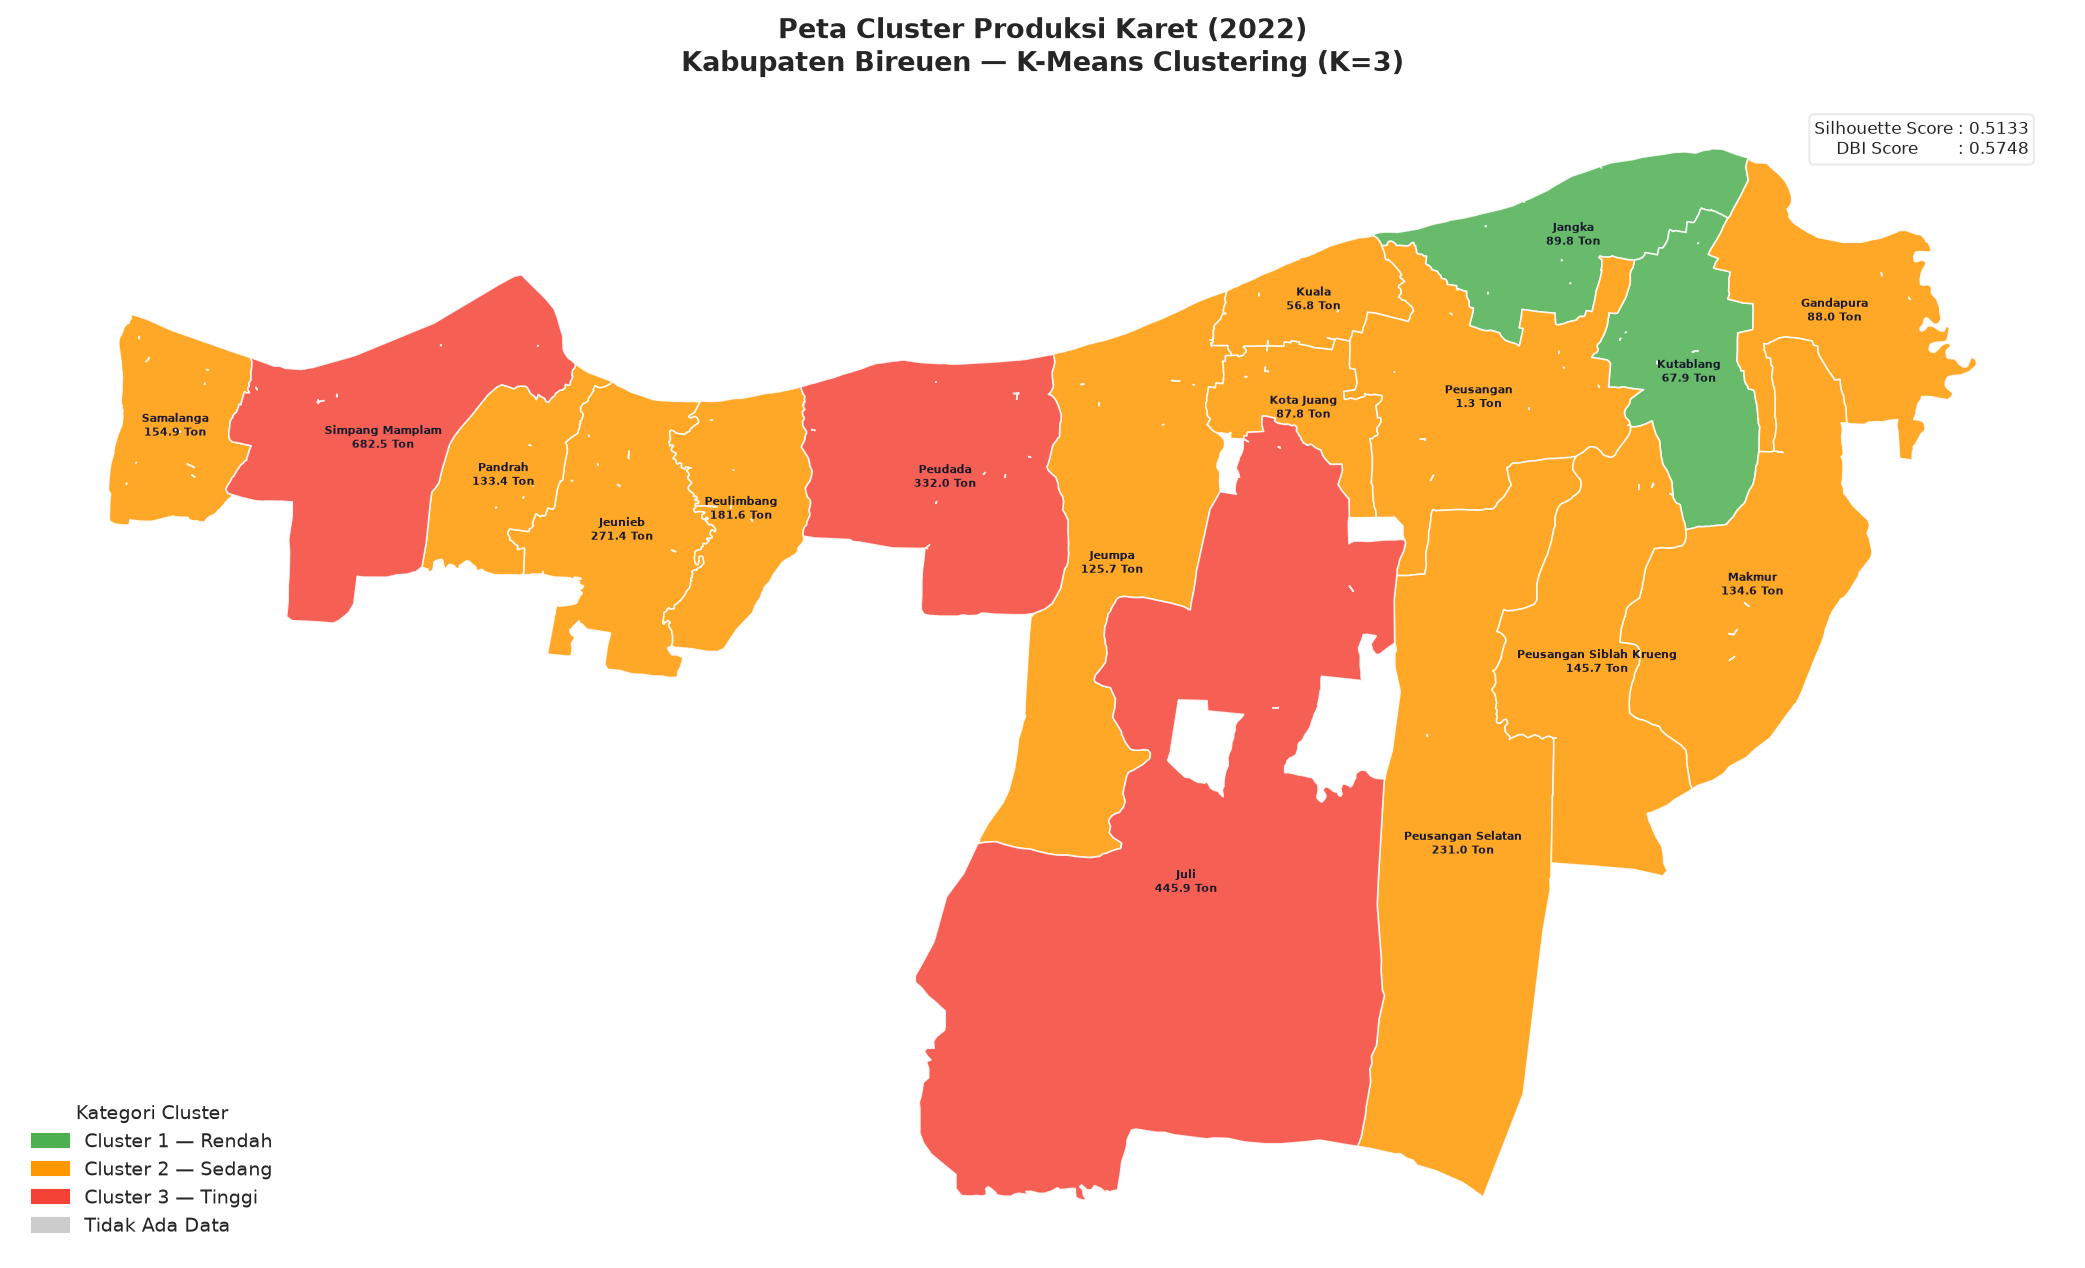

  ✅ Disimpan → static/images/maps/peta_karet_2023.png


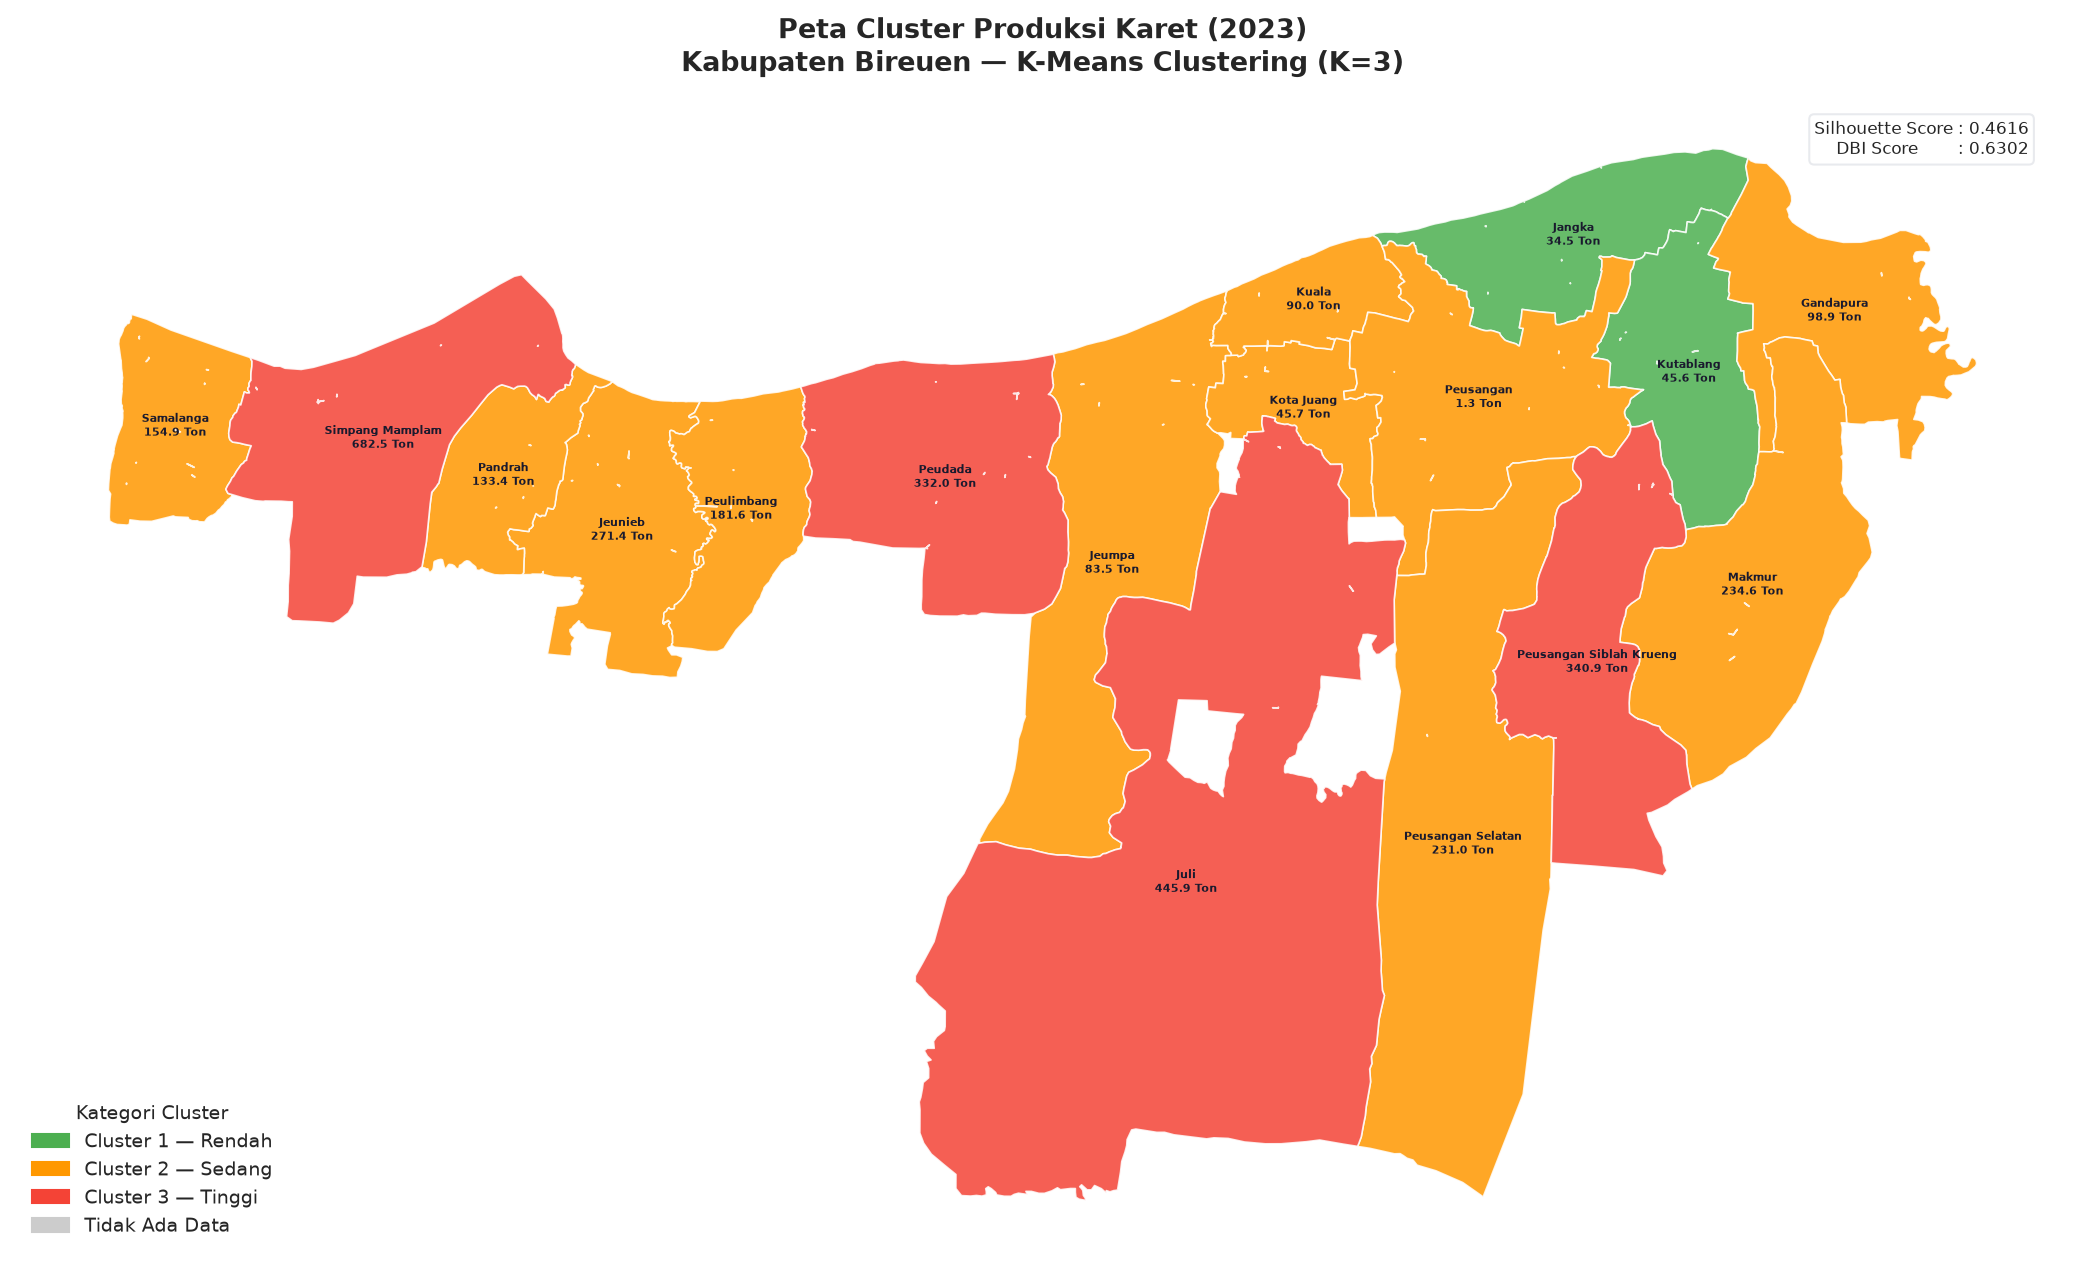

  ✅ Disimpan → static/images/maps/peta_karet_2024.png


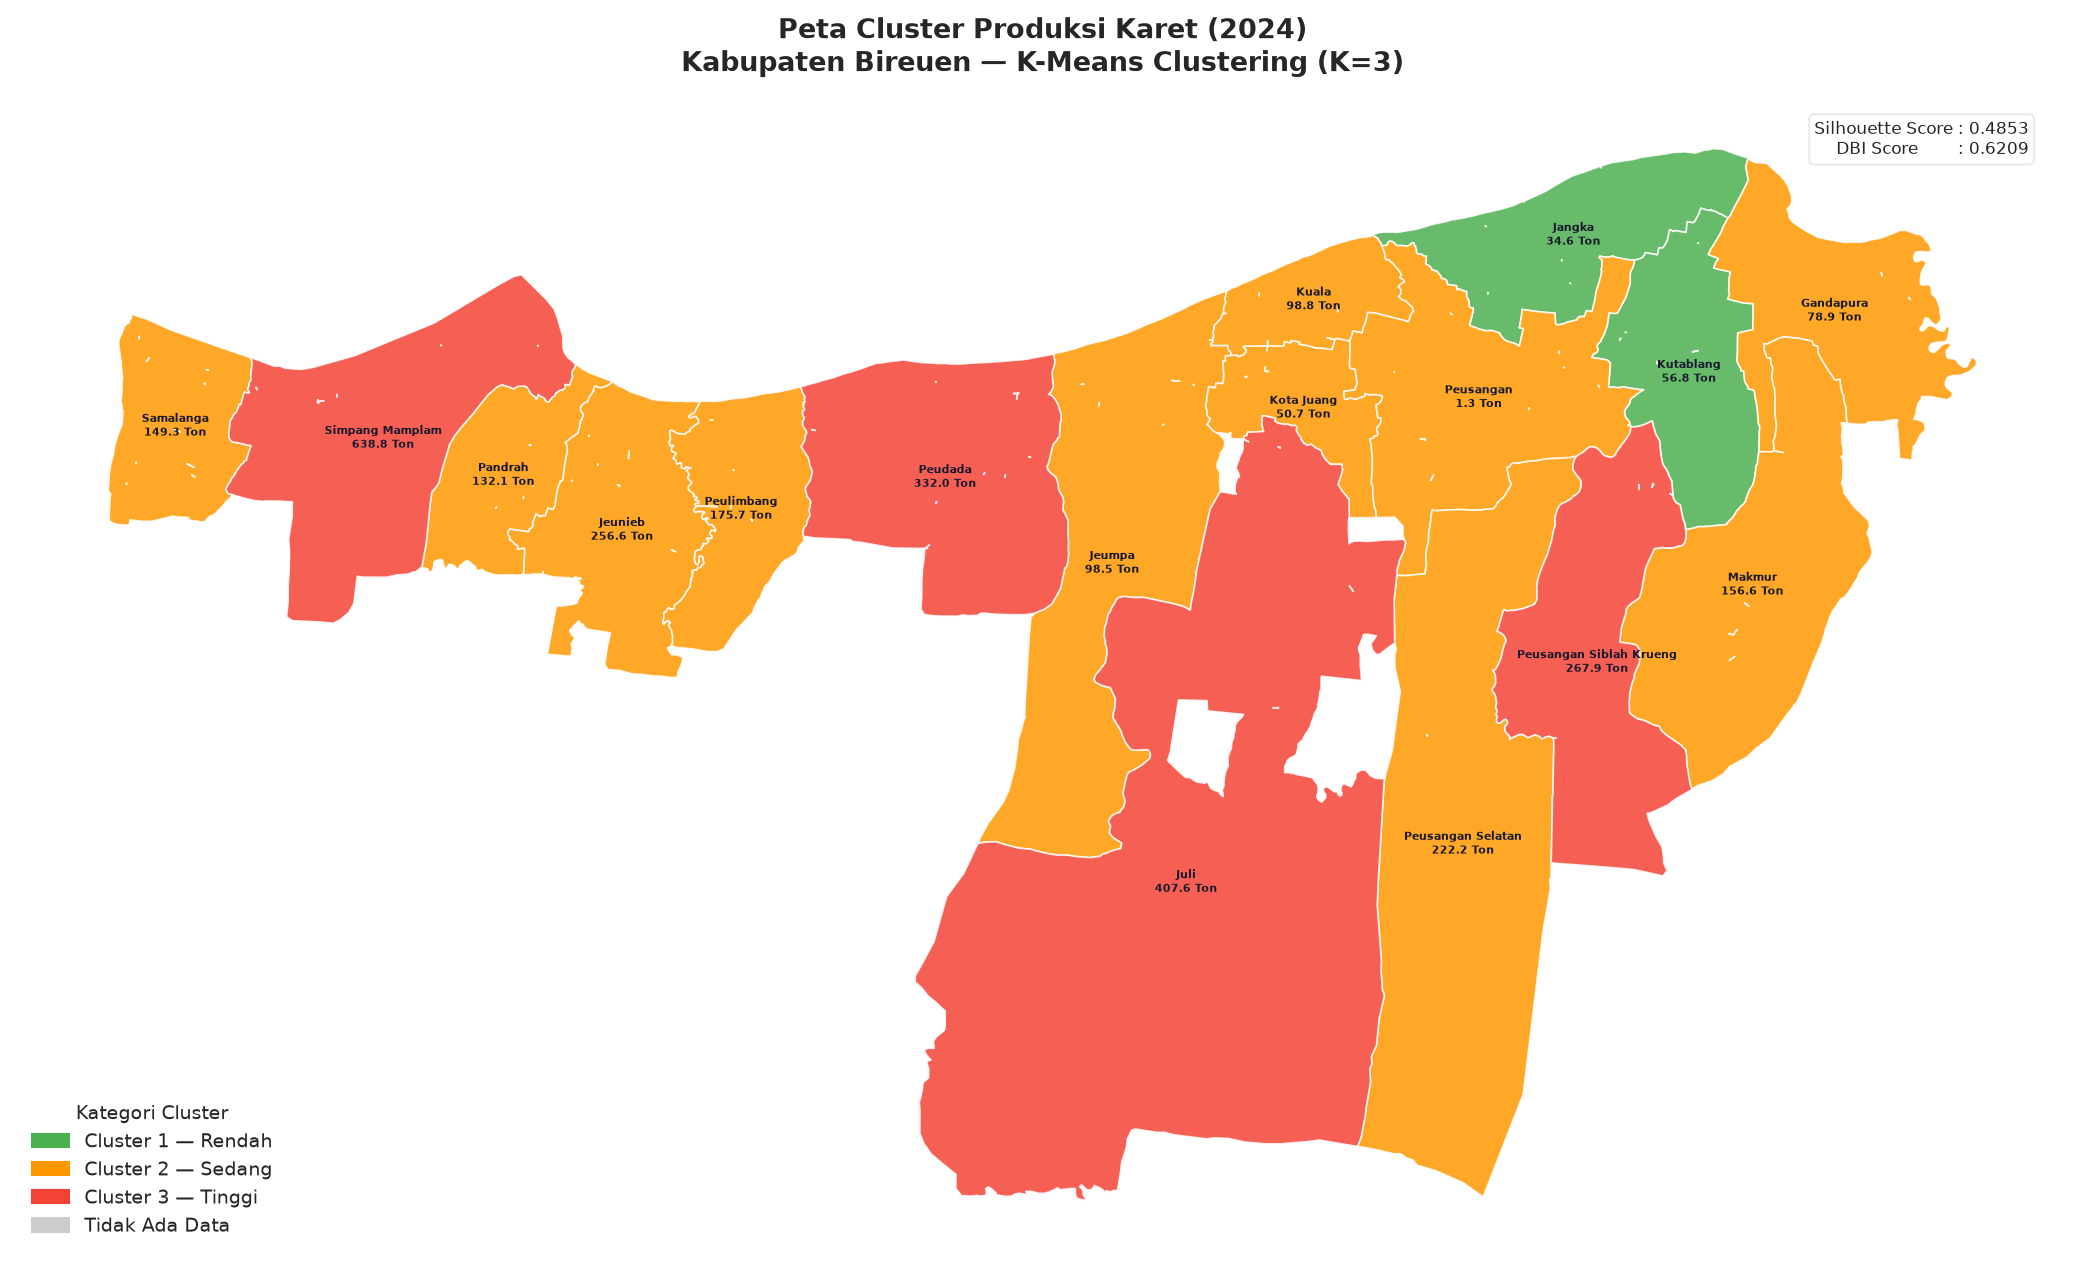


📍 PETA CLUSTER — KELAPA


  ✅ Disimpan → static/images/maps/peta_kelapa_2020.png


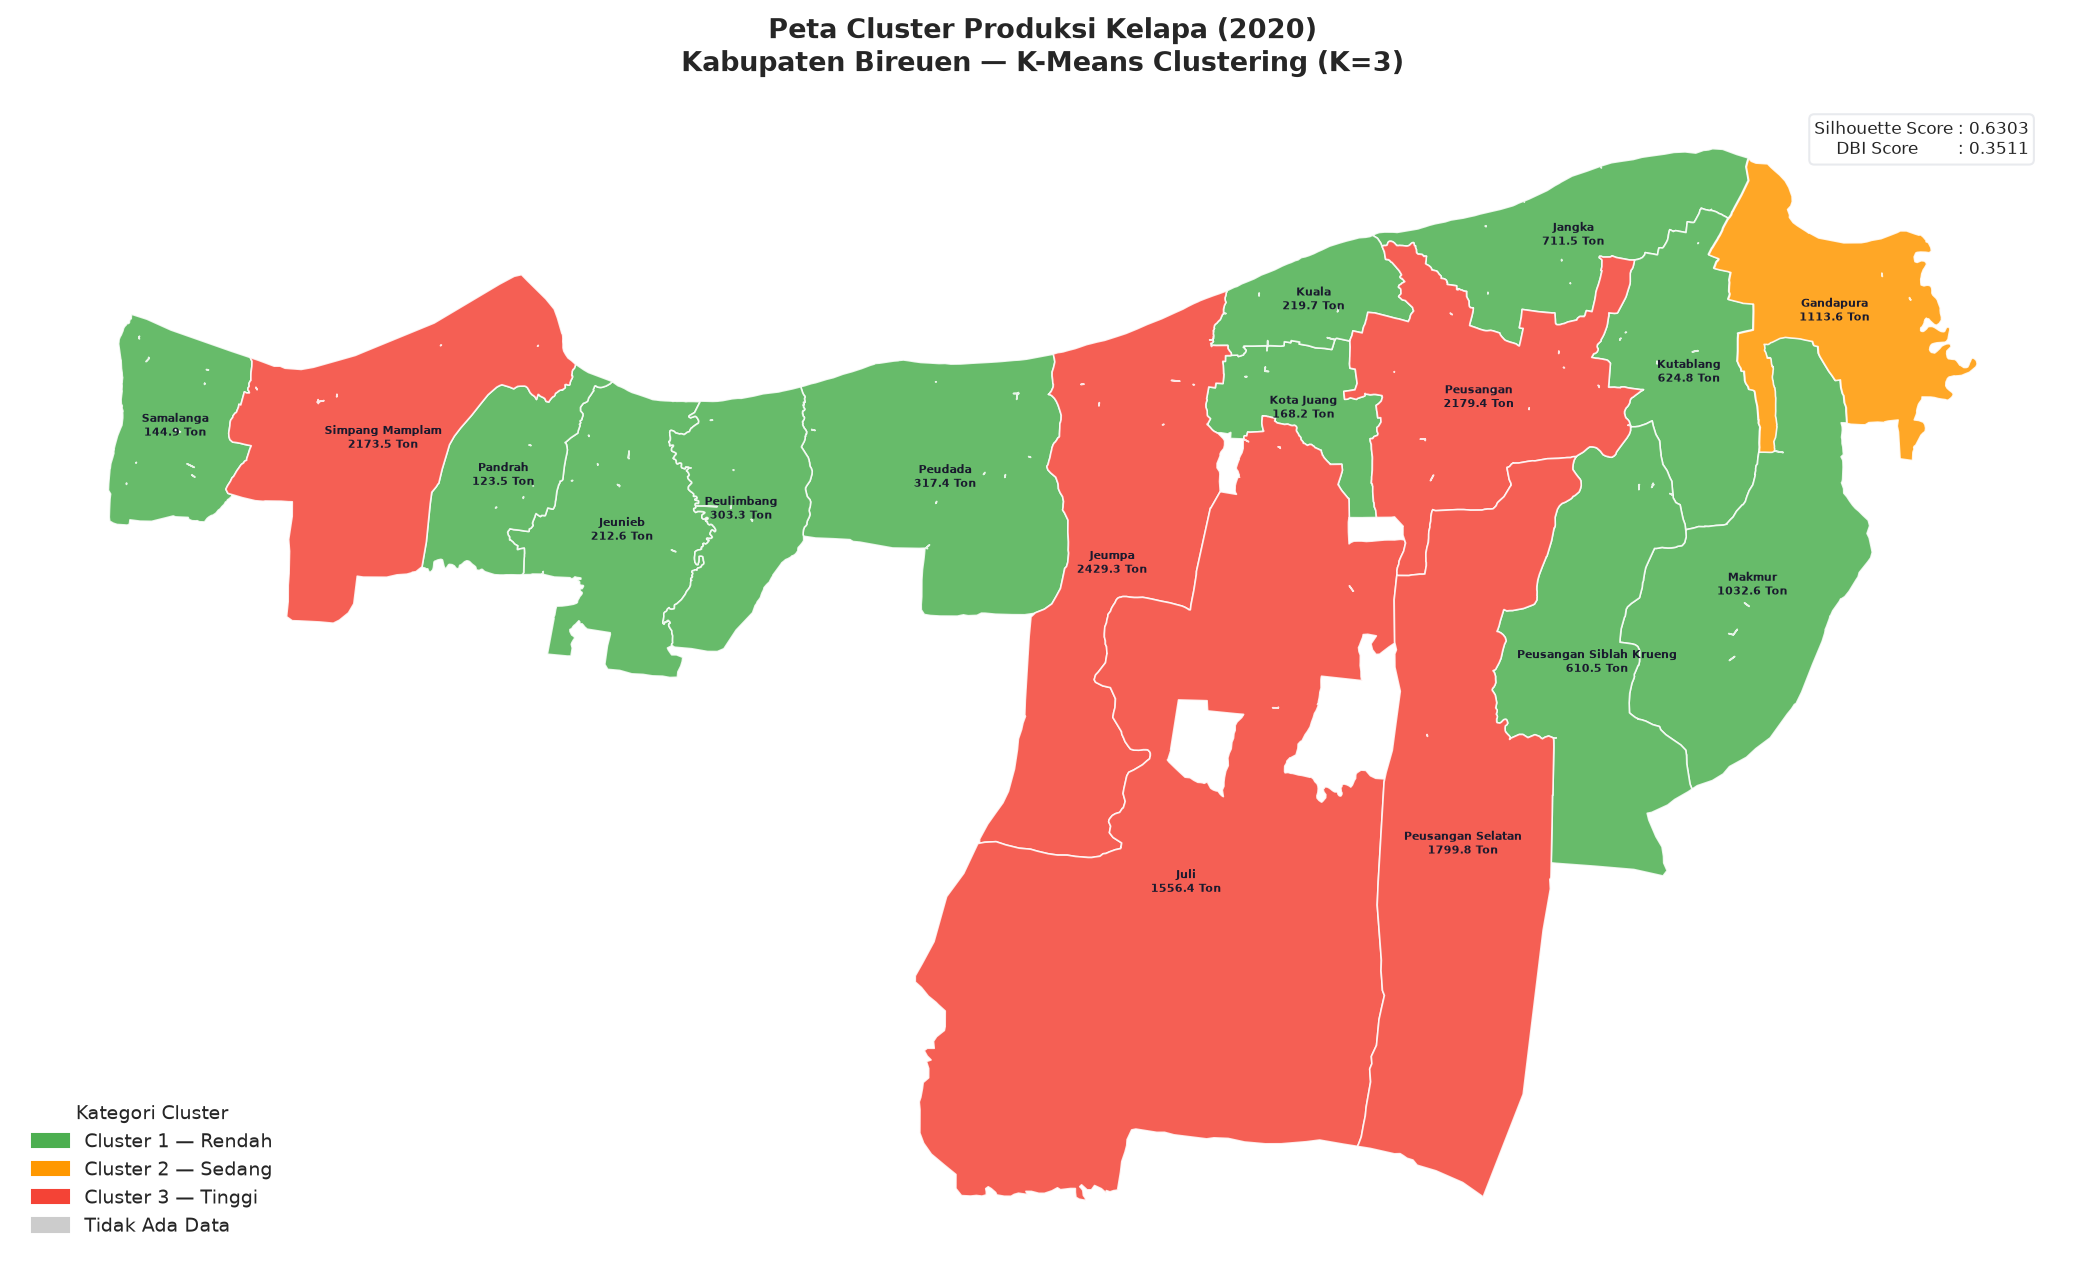

  ✅ Disimpan → static/images/maps/peta_kelapa_2021.png


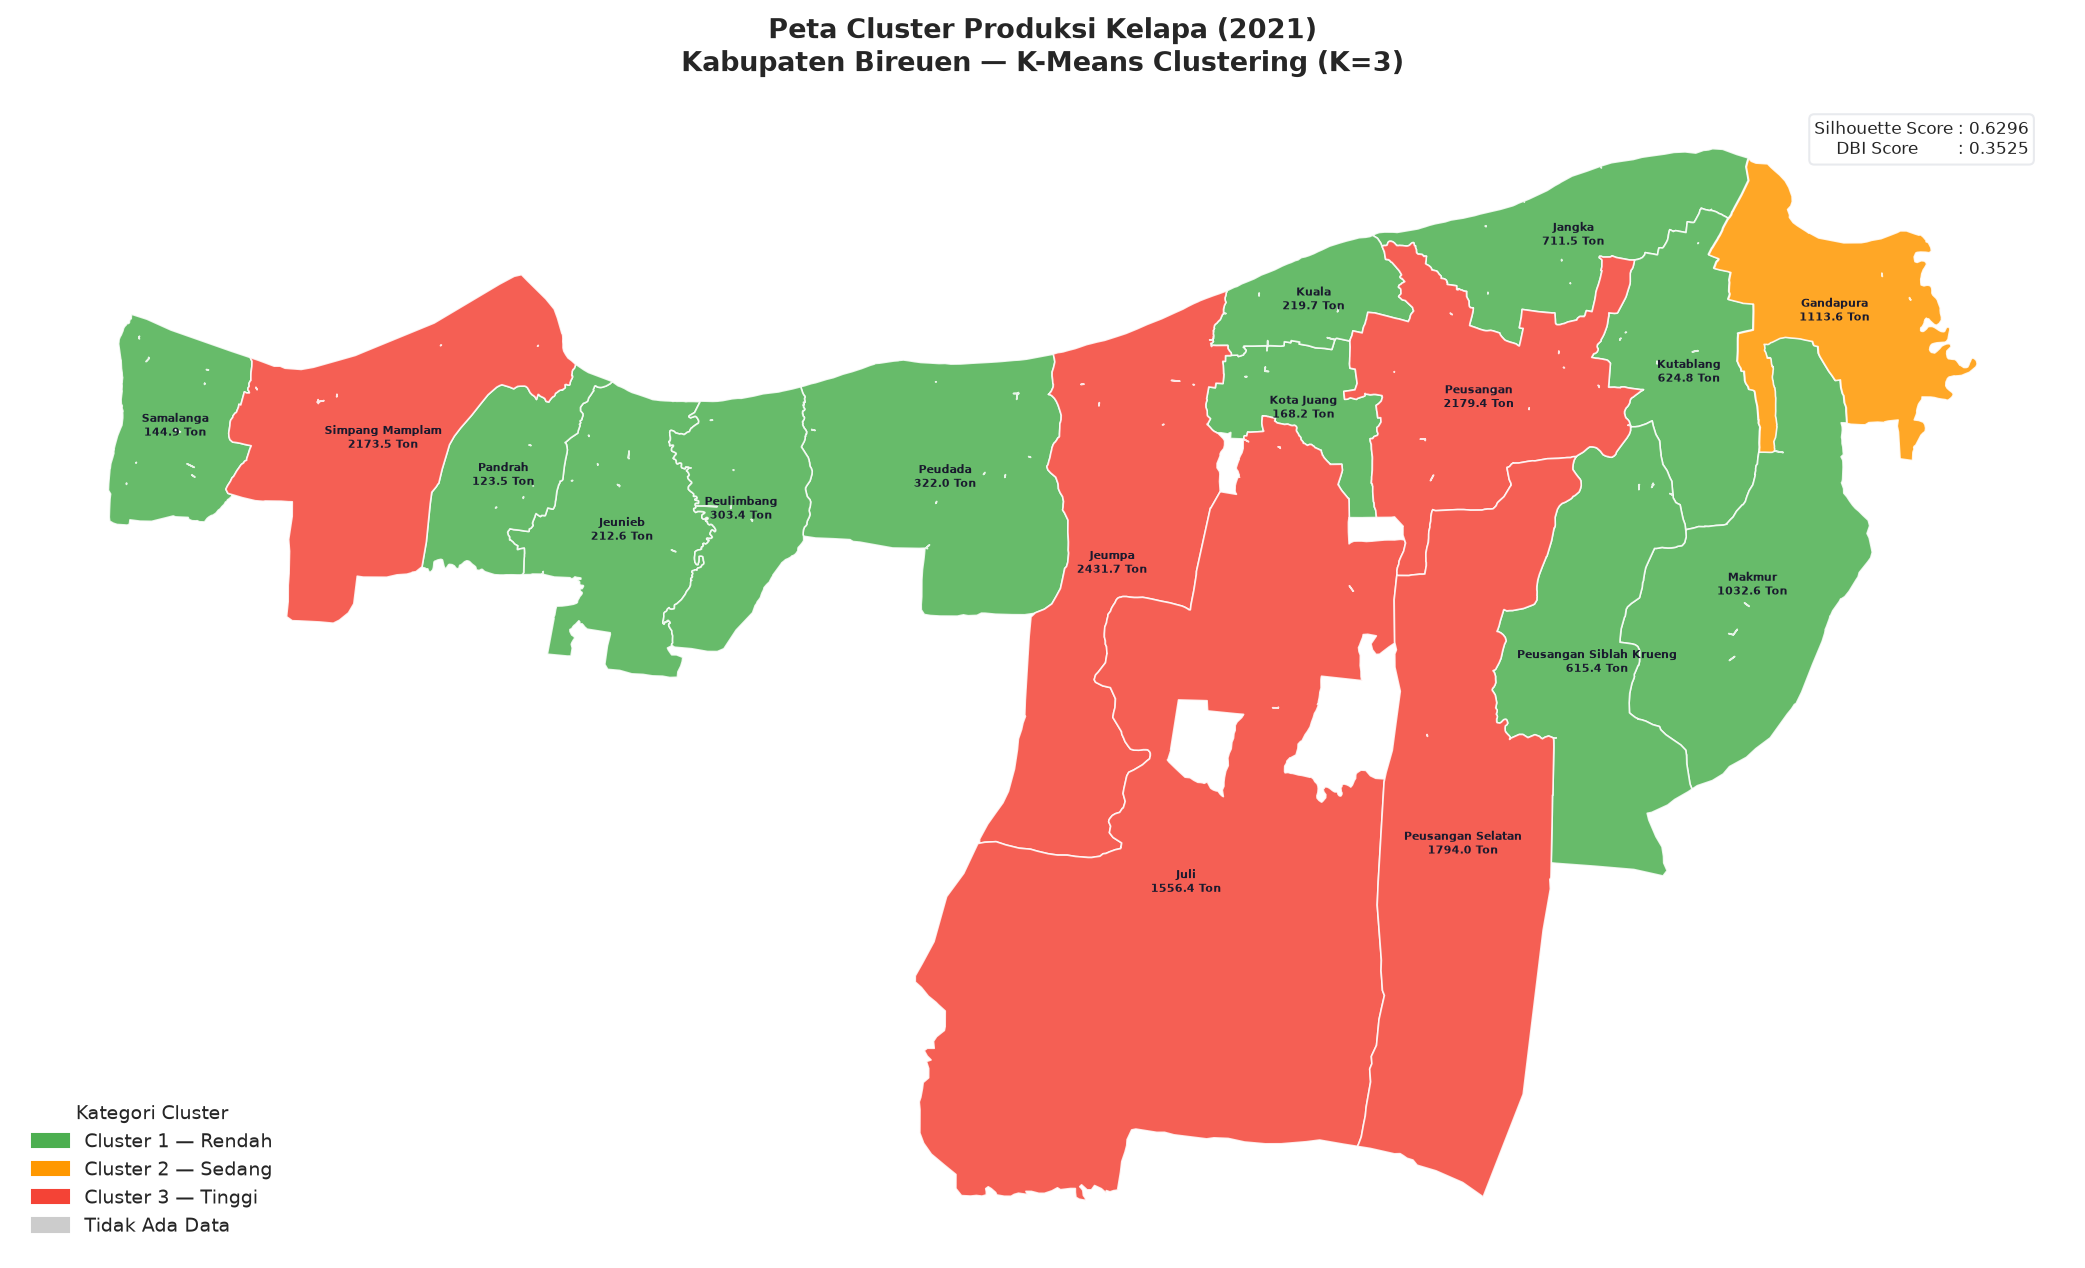

  ✅ Disimpan → static/images/maps/peta_kelapa_2022.png


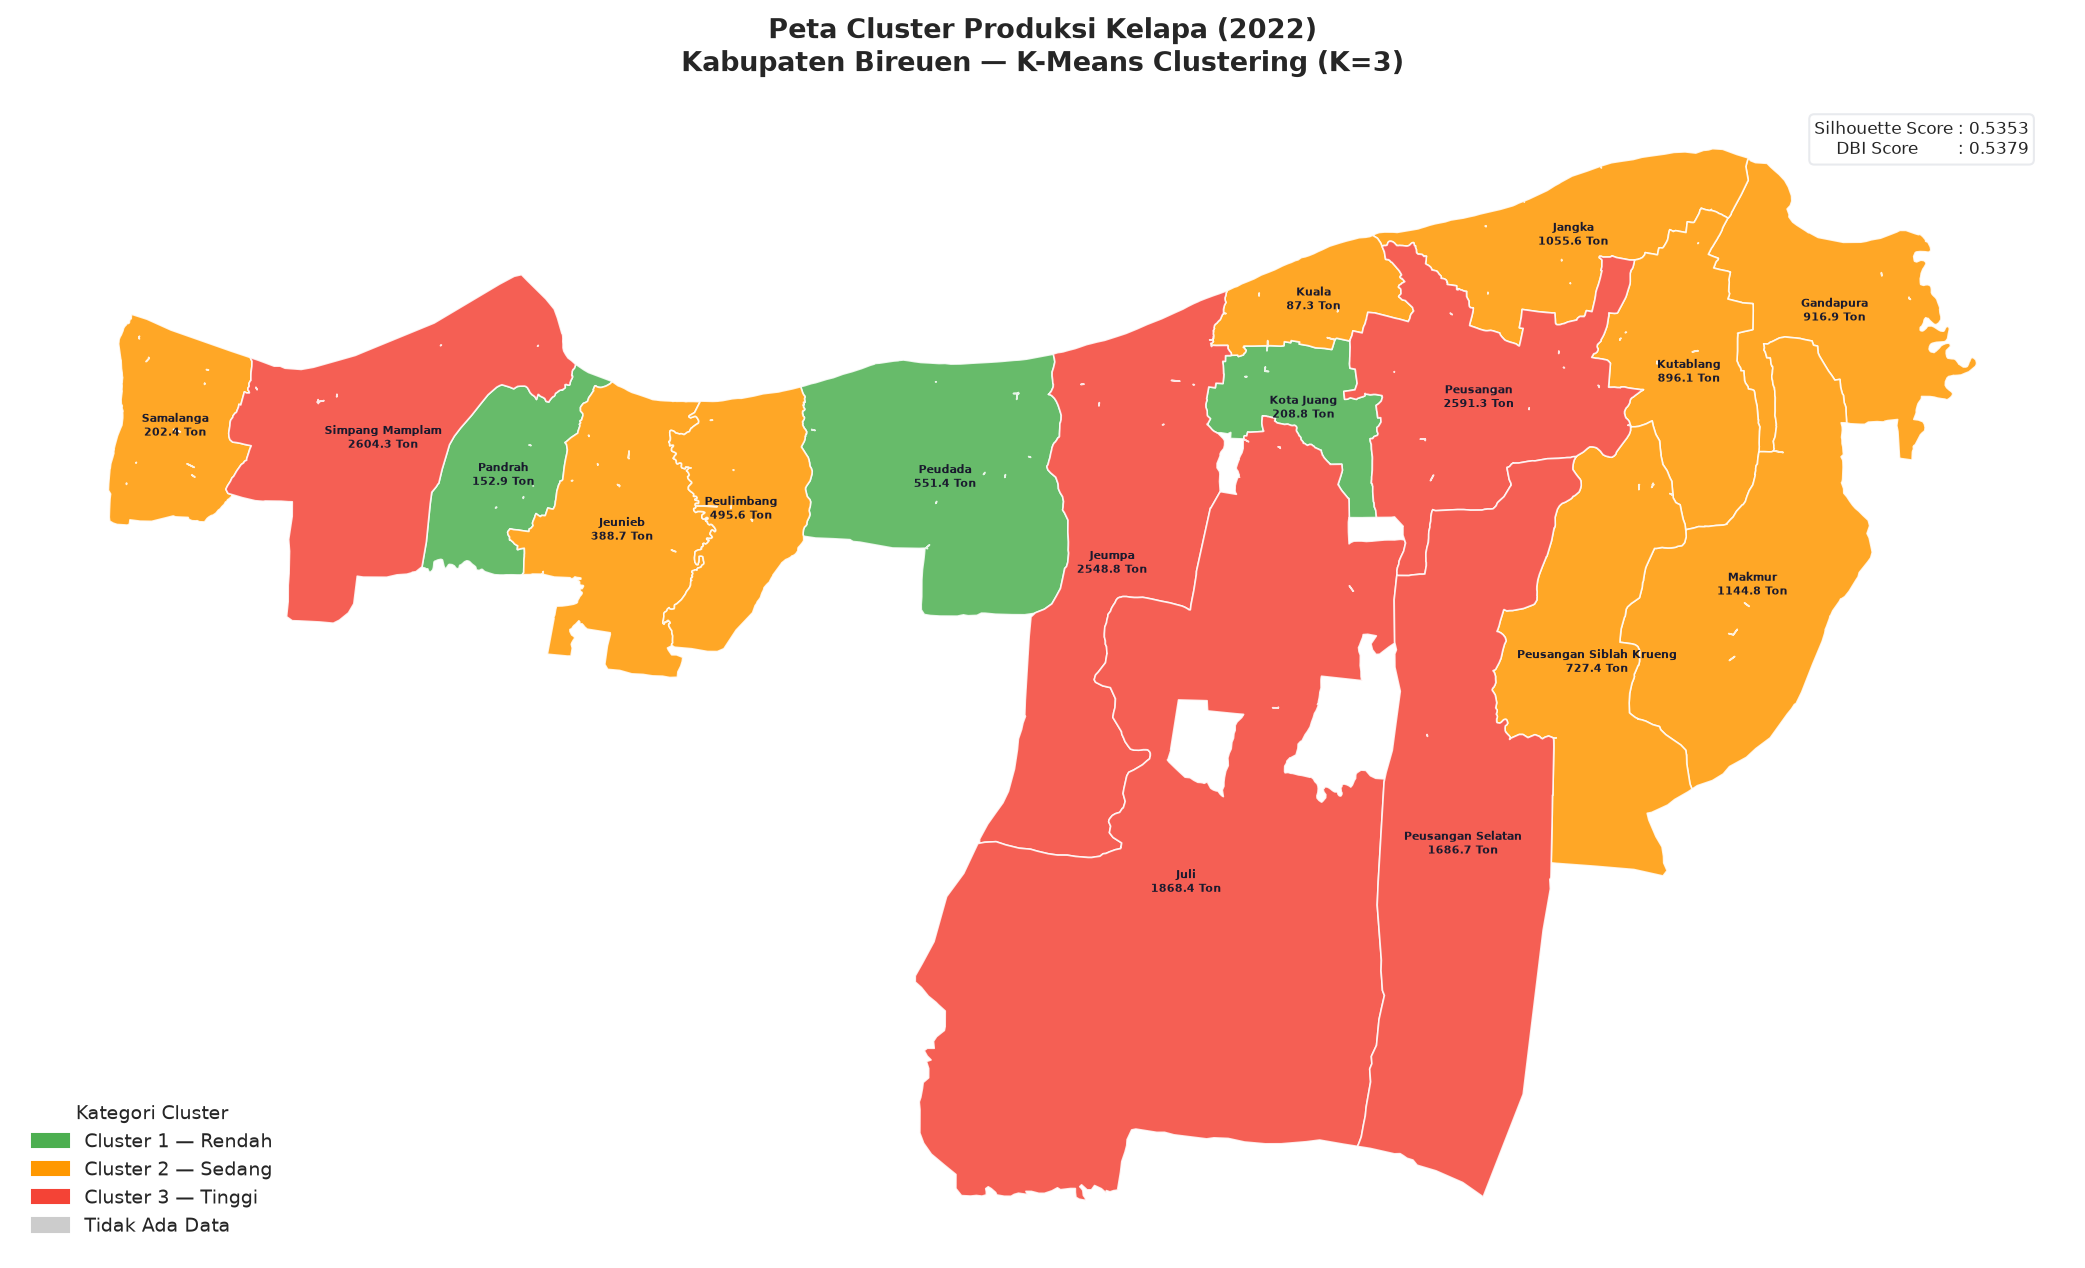

  ✅ Disimpan → static/images/maps/peta_kelapa_2023.png


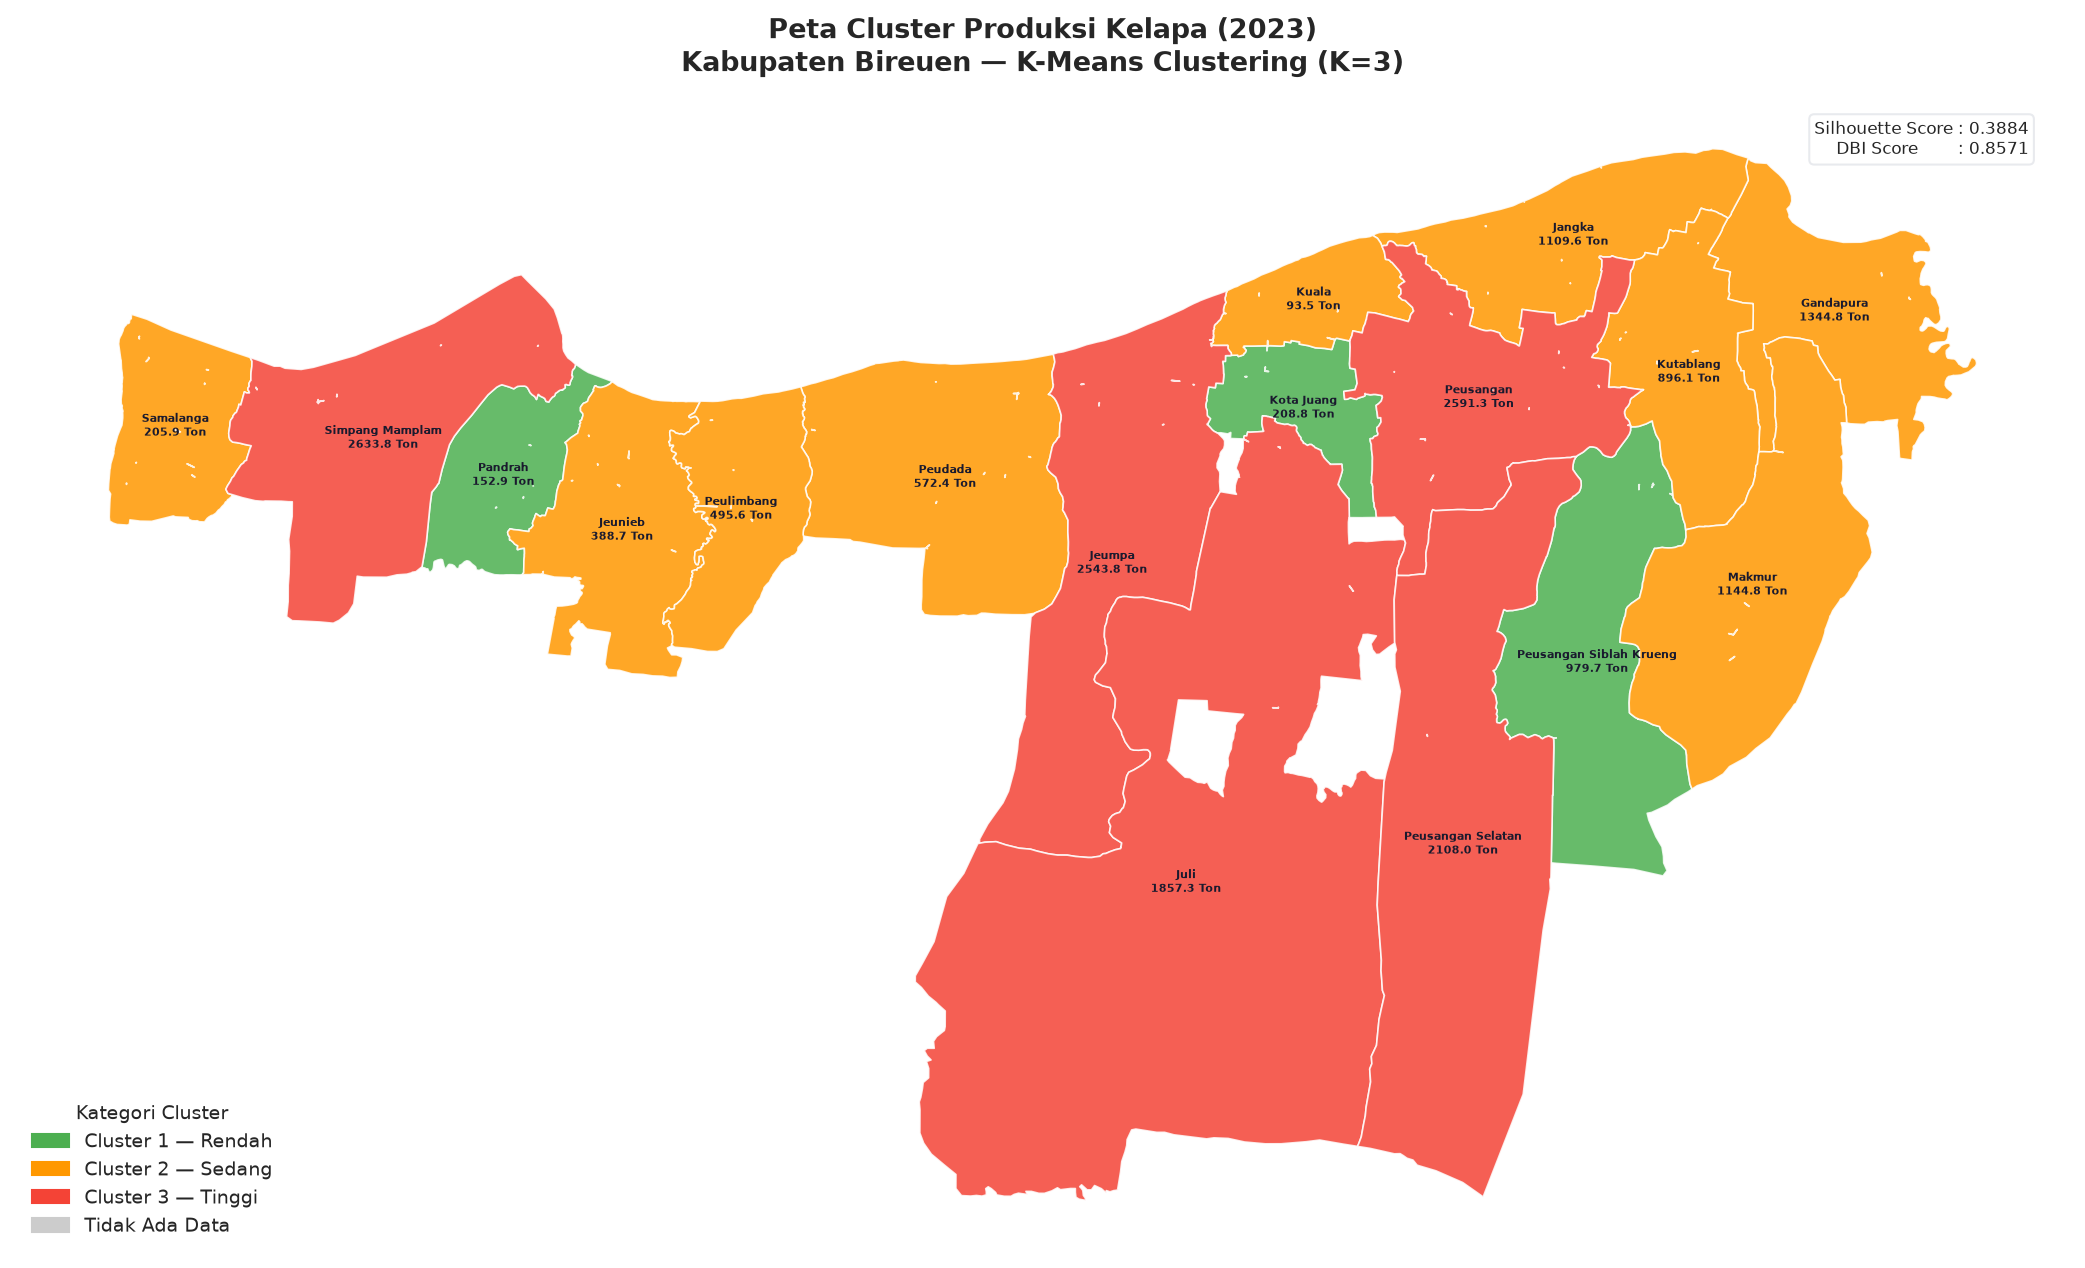

  ✅ Disimpan → static/images/maps/peta_kelapa_2024.png


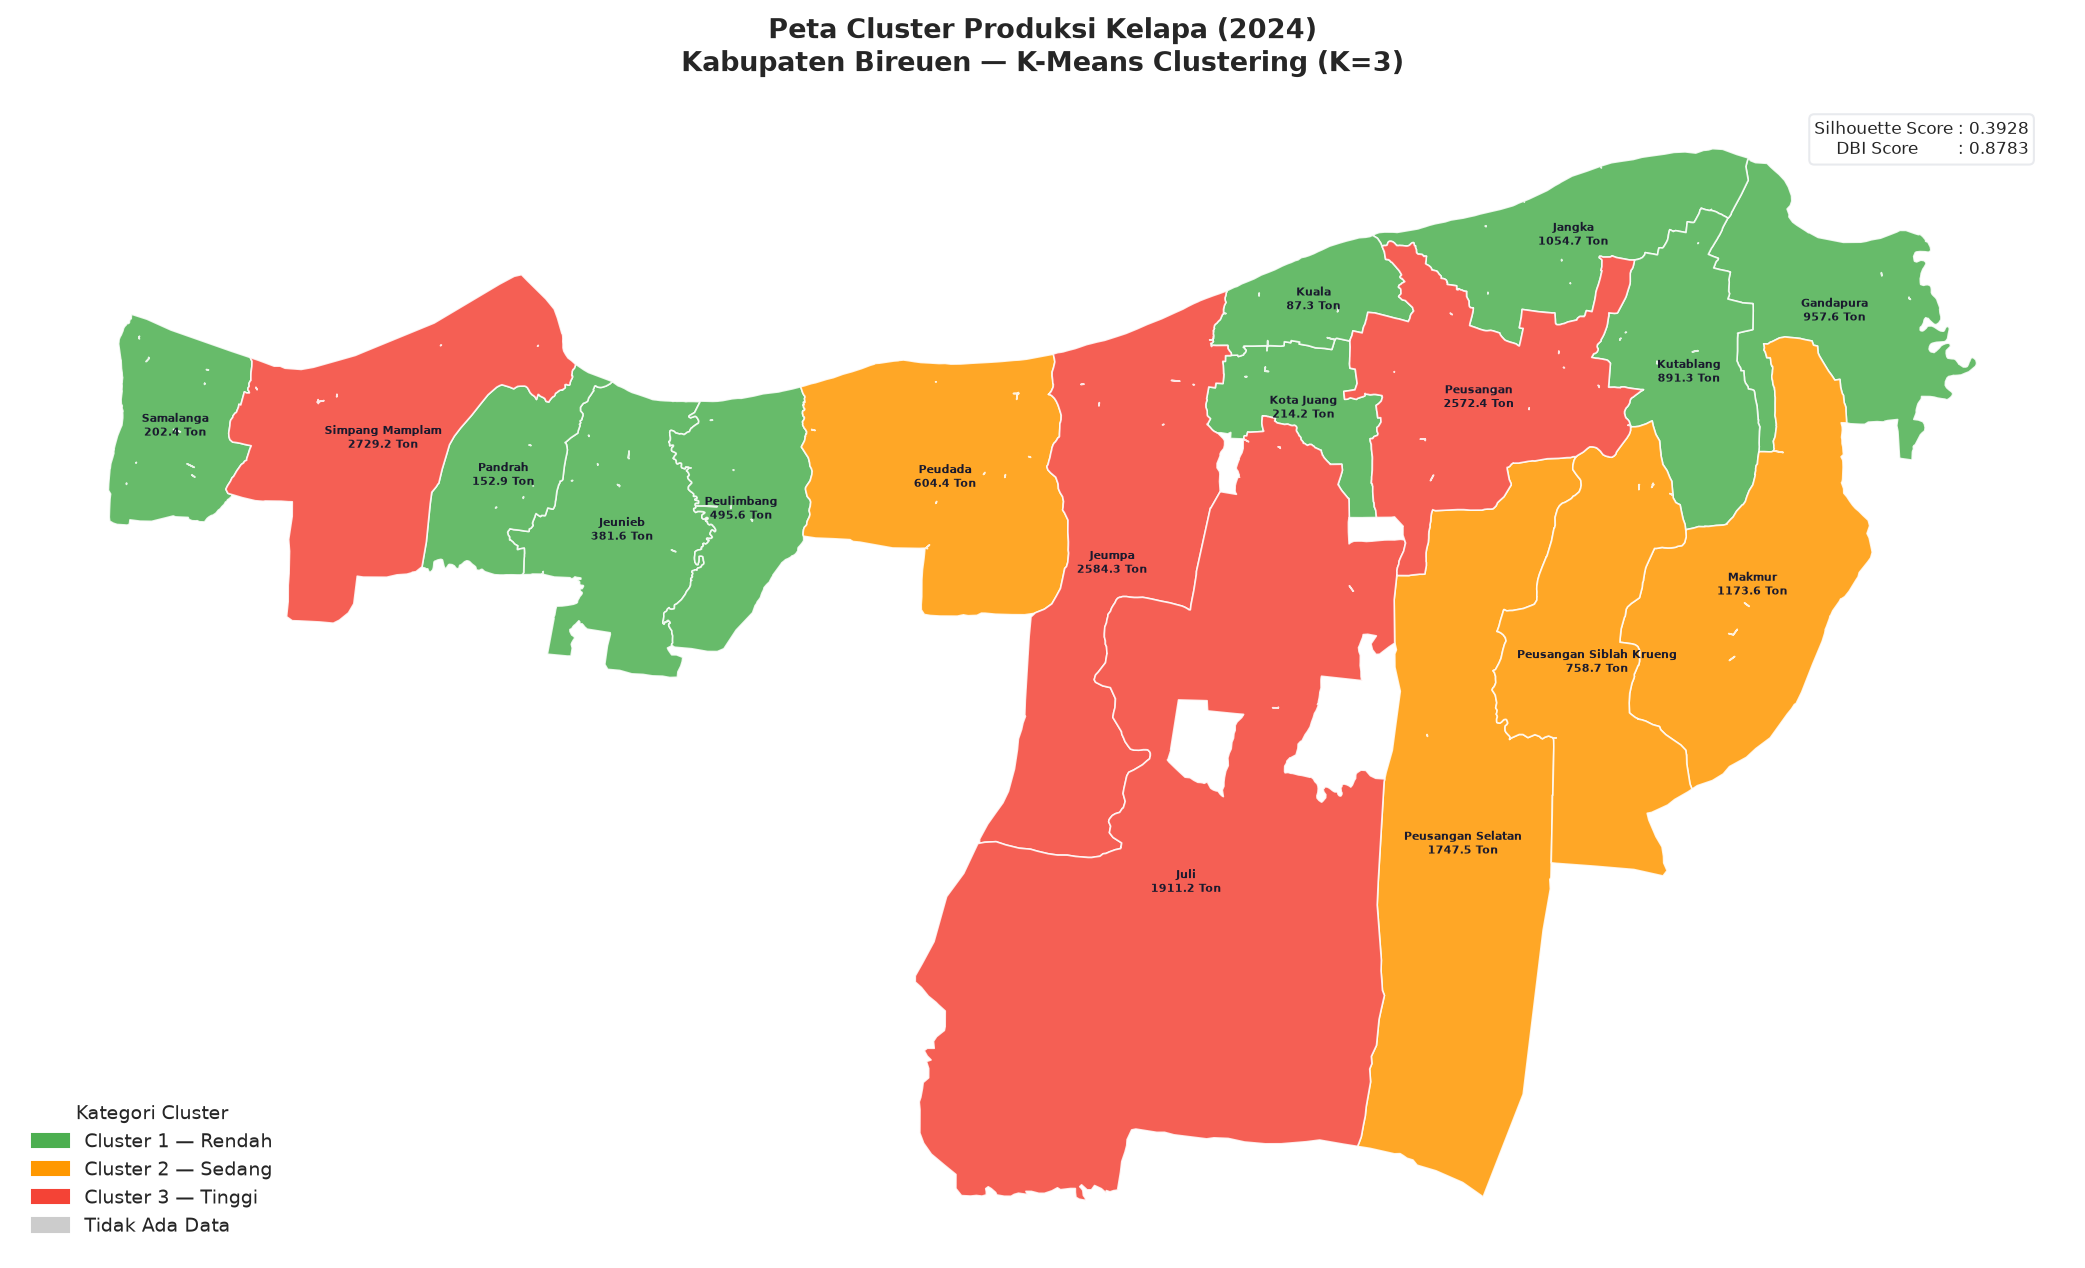


📍 PETA CLUSTER — PINANG


  ✅ Disimpan → static/images/maps/peta_pinang_2020.png


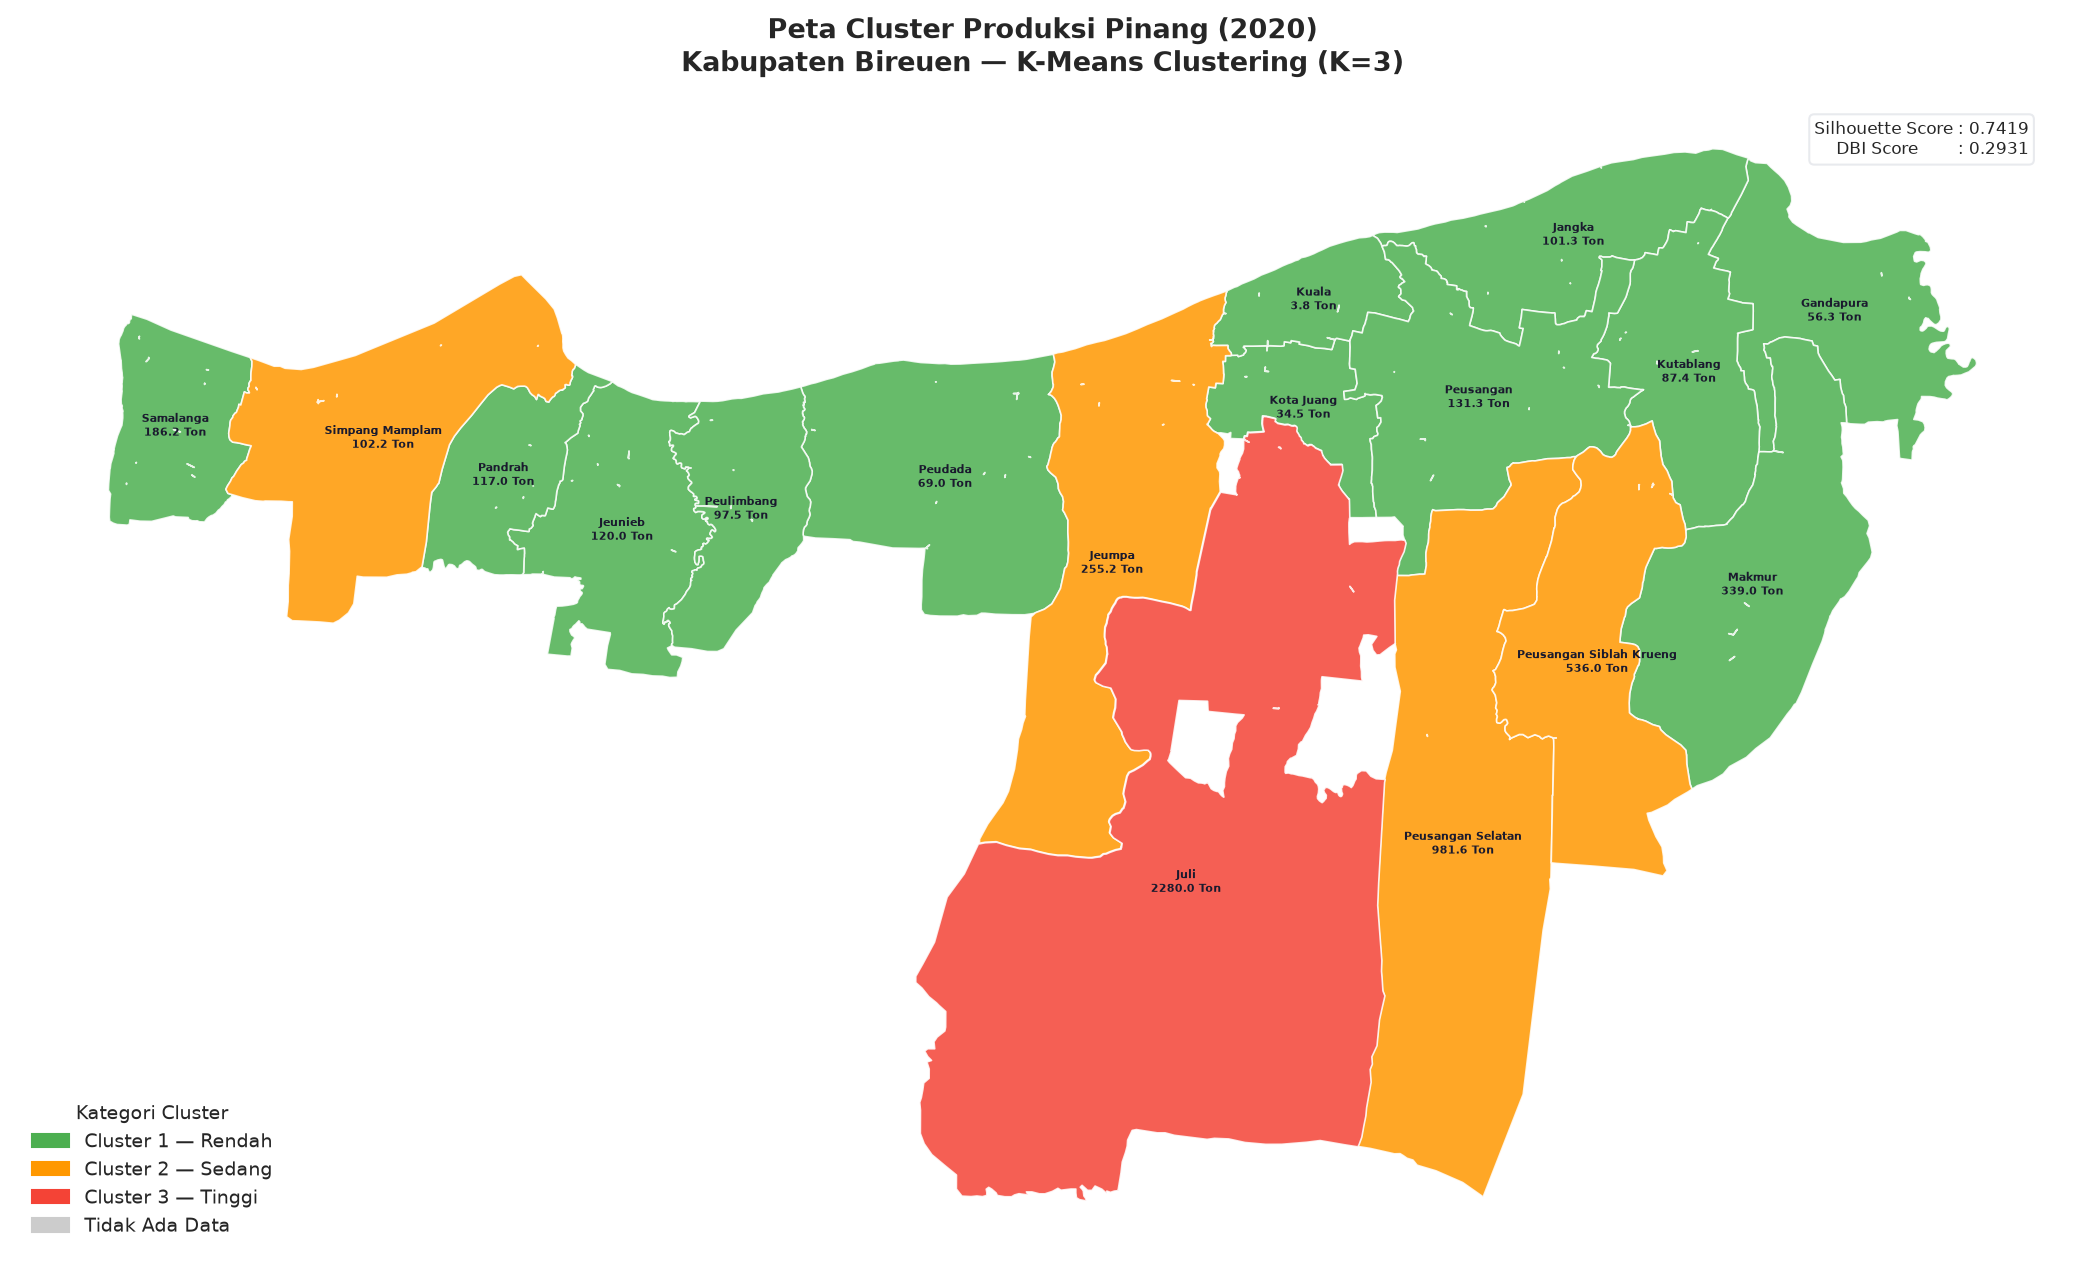

  ✅ Disimpan → static/images/maps/peta_pinang_2021.png


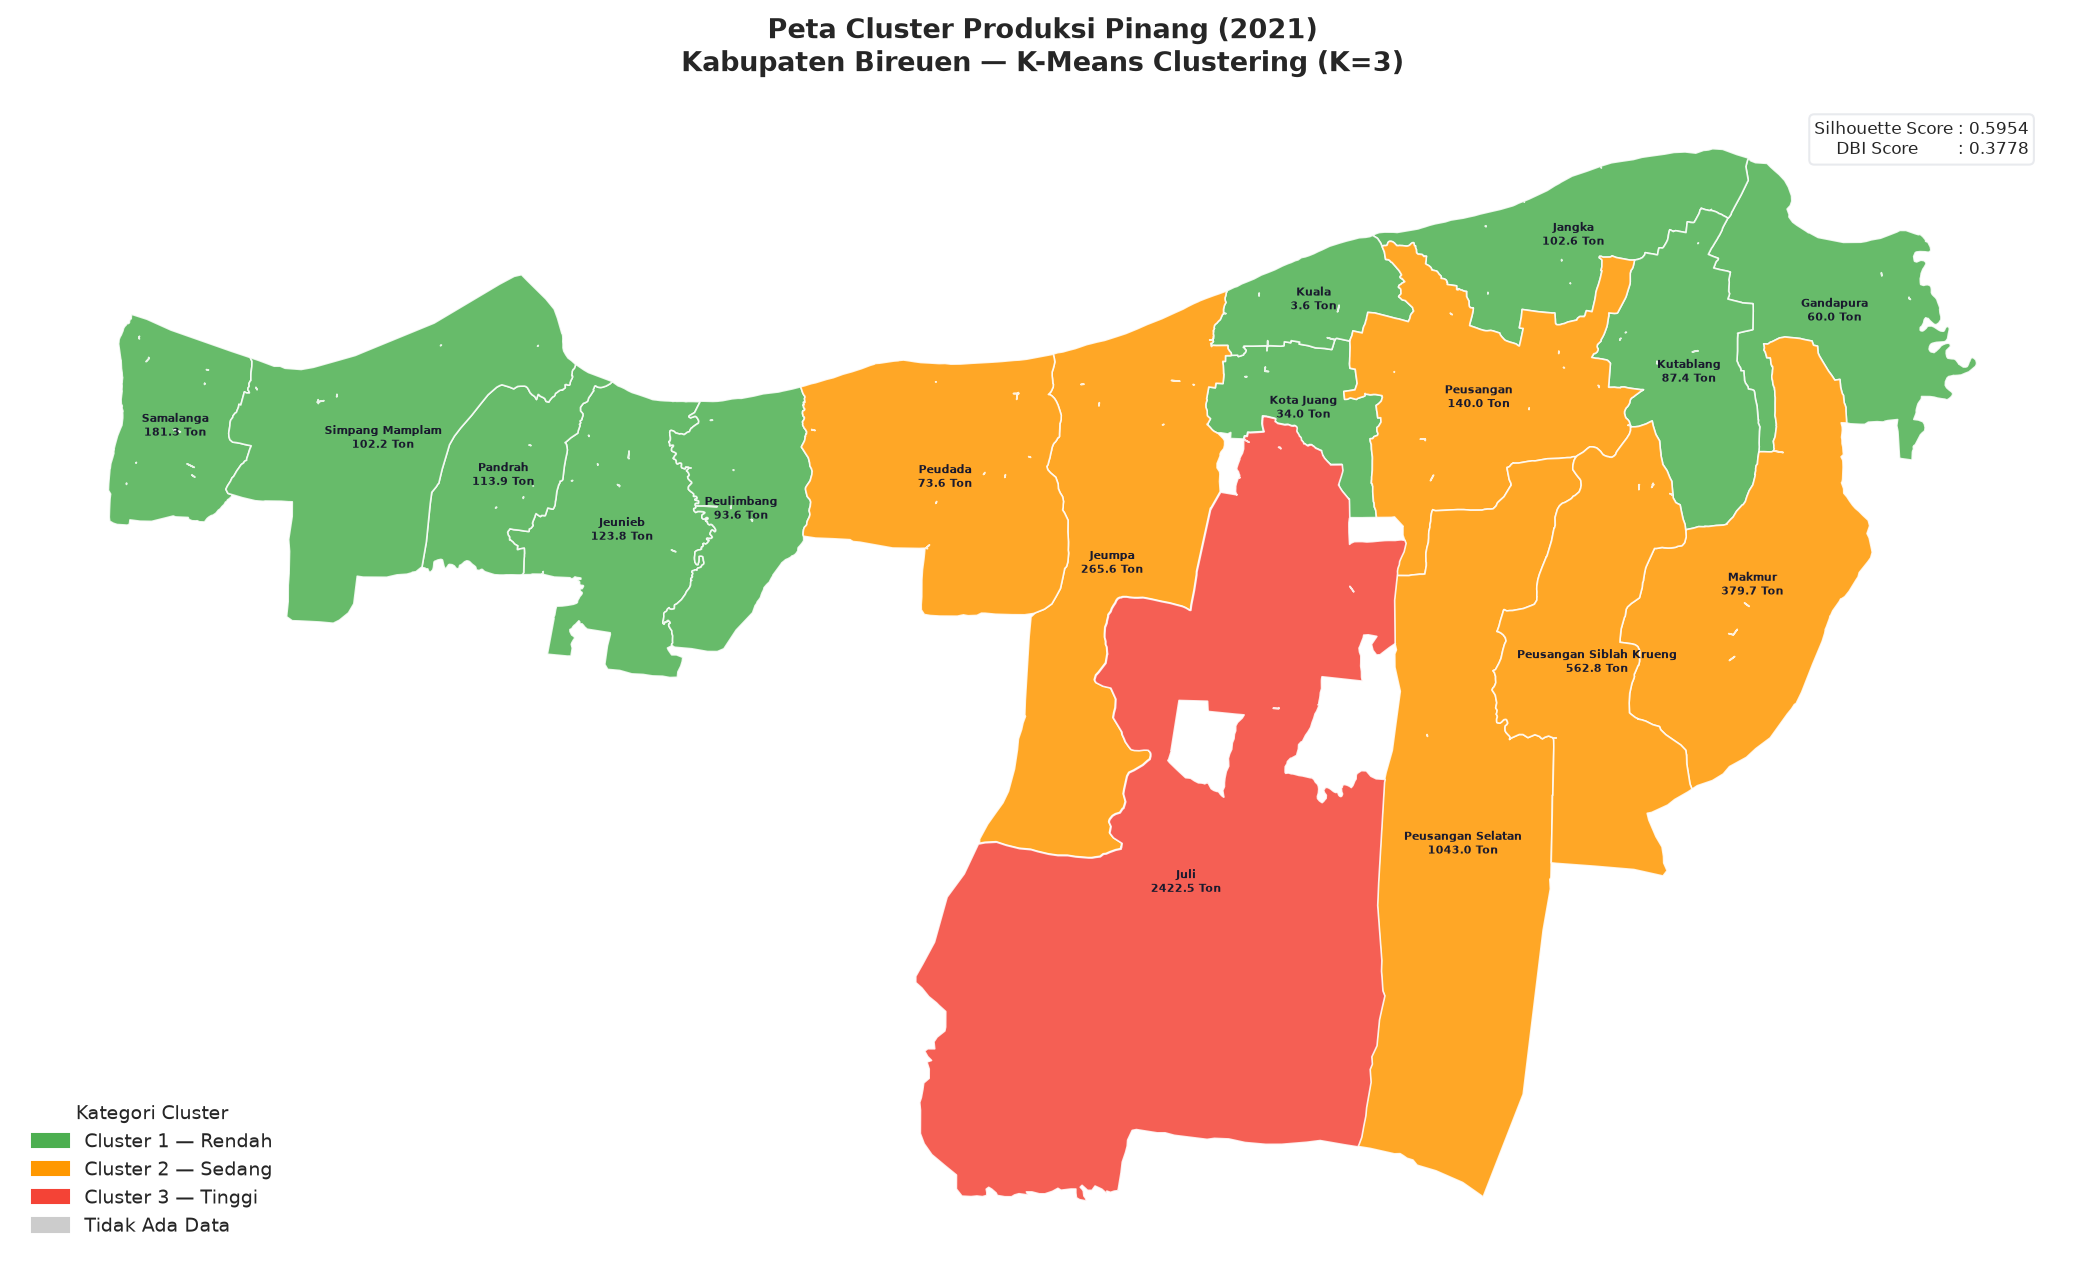

  ✅ Disimpan → static/images/maps/peta_pinang_2022.png


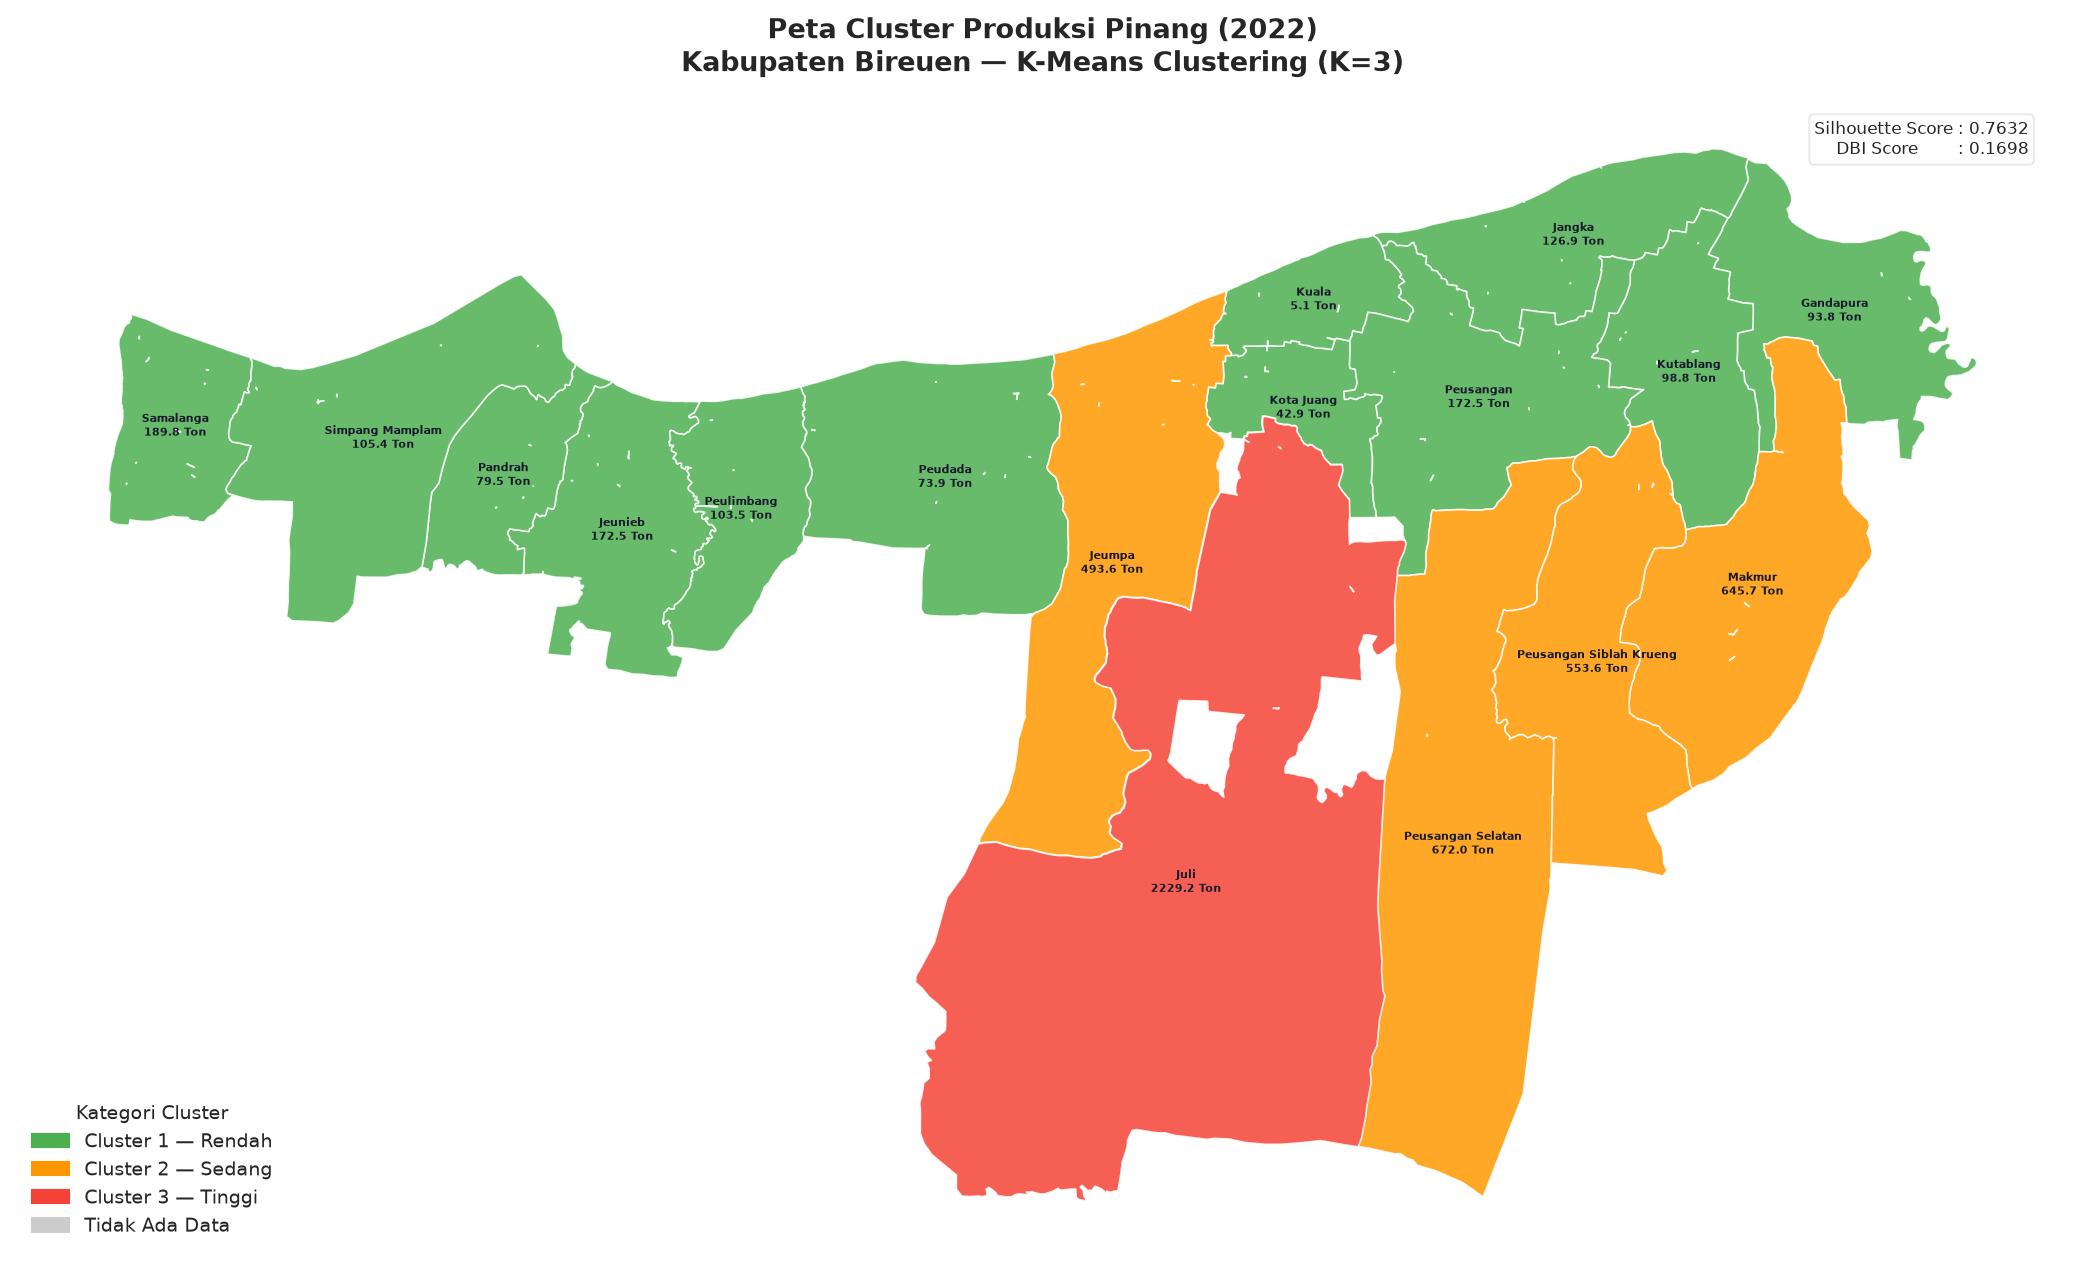

  ✅ Disimpan → static/images/maps/peta_pinang_2023.png


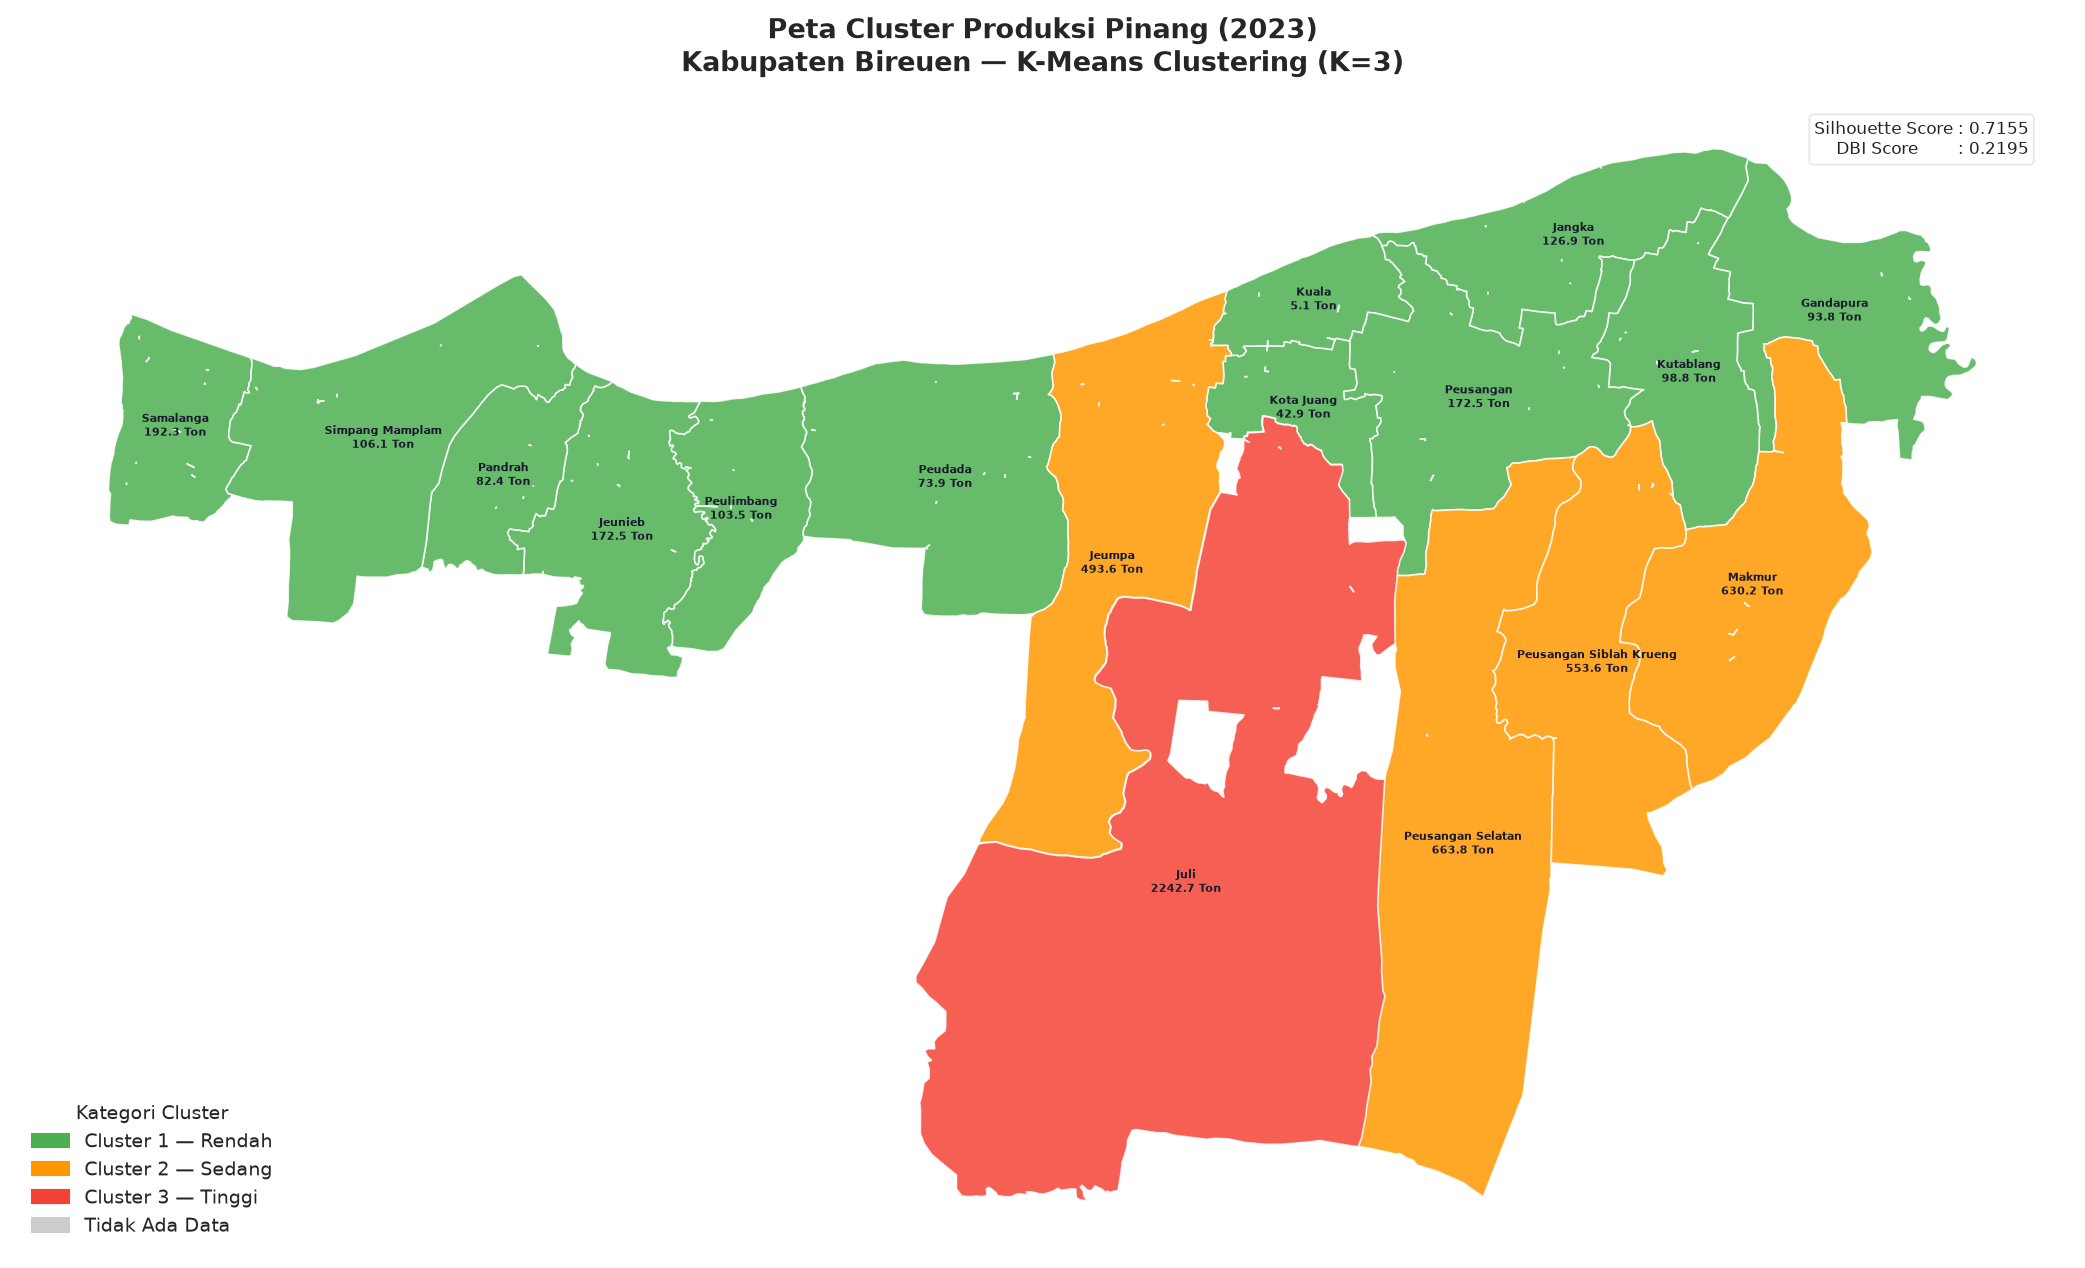

  ✅ Disimpan → static/images/maps/peta_pinang_2024.png


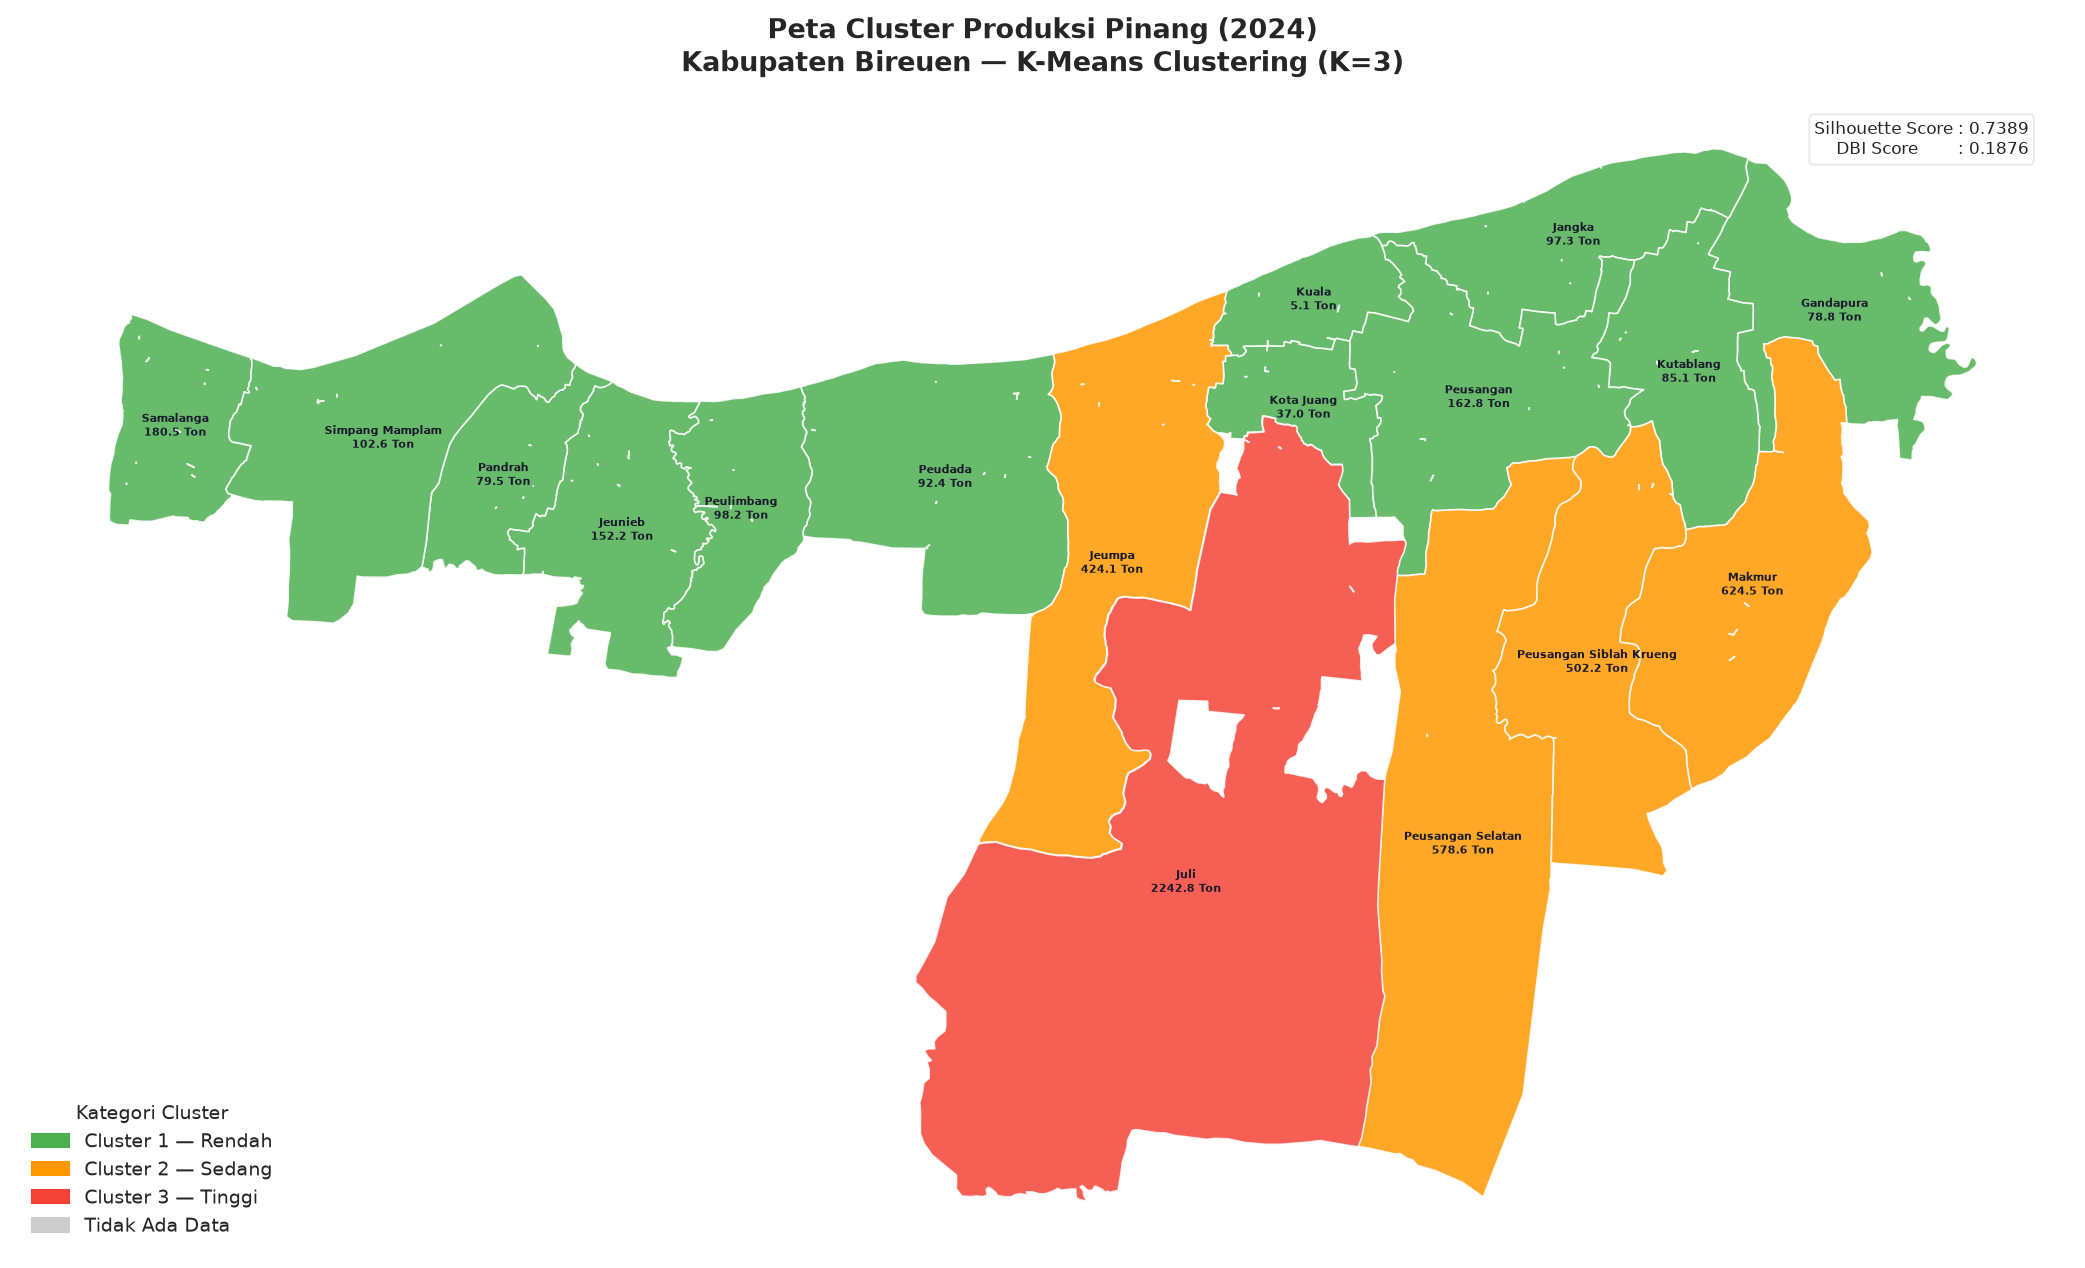


✅ Semua peta cluster berhasil dibuat dan disimpan


In [6]:
# ============================================================
# CELL 6: Visualisasi Peta Cluster per Komoditas per Tahun
# ============================================================

print('VISUALISASI PETA CLUSTER')
print('=' * 55)

def plot_peta_cluster(result, gdf_kec, save_path=None):
    """
    Plot peta choropleth cluster per kecamatan.
    """
    komoditas = result['komoditas']
    tahun     = result['tahun']
    df_res    = result['df_result'][
        ['Kecamatan', 'Cluster', 'Cluster_Nama',
         'Produksi_Ton', 'Produktivitas_KgHa']
    ].copy()

    # Merge dengan shapefile
    gdf_merged = gdf_kec.merge(df_res, on='Kecamatan', how='left')

    # Warna per kategori
    color_map = {
        'Rendah': '#4CAF50',
        'Sedang': '#FF9800',
        'Tinggi': '#F44336',
        None    : '#CCCCCC'
    }
    gdf_merged['color'] = gdf_merged['Cluster_Nama'].map(color_map).fillna('#CCCCCC')

    fig, ax = plt.subplots(figsize=(14, 9))

    # Plot per kategori
    for kategori, color in color_map.items():
        if kategori is None:
            continue
        subset = gdf_merged[gdf_merged['Cluster_Nama'] == kategori]
        if len(subset) > 0:
            subset.plot(
                color=color,
                edgecolor='white',
                linewidth=0.8,
                ax=ax,
                alpha=0.85
            )

    # Plot kecamatan tanpa data (abu-abu)
    no_data = gdf_merged[gdf_merged['Cluster_Nama'].isna()]
    if len(no_data) > 0:
        no_data.plot(
            color='#CCCCCC',
            edgecolor='white',
            linewidth=0.8,
            ax=ax
        )

    # Label kecamatan + nilai produksi
    for idx, row in gdf_merged.iterrows():
        if row.geometry and not pd.isna(row.get('Kecamatan')):
            cx = row.geometry.centroid.x
            cy = row.geometry.centroid.y
            label = row['Kecamatan'] or ''
            prod  = f"\n{row['Produksi_Ton']:.1f} Ton" \
                    if not pd.isna(row.get('Produksi_Ton')) else ''
            ax.annotate(
                text=f"{label}{prod}",
                xy=(cx, cy),
                fontsize=5.5,
                ha='center',
                va='center',
                color='#1A1A2E',
                fontweight='bold'
            )

    # Legend
    legend_patches = [
        mpatches.Patch(color='#4CAF50', label='Cluster 1 — Rendah'),
        mpatches.Patch(color='#FF9800', label='Cluster 2 — Sedang'),
        mpatches.Patch(color='#F44336', label='Cluster 3 — Tinggi'),
        mpatches.Patch(color='#CCCCCC', label='Tidak Ada Data'),
    ]
    ax.legend(
        handles=legend_patches,
        loc='lower left',
        fontsize=9,
        framealpha=0.9,
        title='Kategori Cluster',
        title_fontsize=9
    )

    # Evaluasi di pojok kanan atas
    sil = result['silhouette_score']
    dbi = result['dbi_score']
    info = f"Silhouette Score : {sil}\nDBI Score        : {dbi}"
    ax.text(
        0.98, 0.98, info,
        transform=ax.transAxes,
        fontsize=8,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85,
                  edgecolor='#E5E7EB')
    )

    ax.set_title(
        f'Peta Cluster Produksi {komoditas} ({tahun})\n'
        f'Kabupaten Bireuen — K-Means Clustering (K=3)',
        fontsize=13, fontweight='bold', pad=12
    )
    ax.set_axis_off()
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'  ✅ Disimpan → {save_path}')

    plt.show()
    plt.close()


# Generate semua peta
for komoditas in KOMODITAS_LIST:
    print(f'\n📍 PETA CLUSTER — {komoditas.upper()}')
    for tahun in YEARS:
        result    = all_results[komoditas][tahun]
        save_path = (f'static/images/maps/'
                     f'peta_{komoditas.lower()}_{tahun}.png')
        plot_peta_cluster(result, gdf_kec, save_path=save_path)

print('\n✅ Semua peta cluster berhasil dibuat dan disimpan')

VISUALISASI GRAFIK EVALUASI & DISTRIBUSI CLUSTER

📊 GRAFIK — KARET


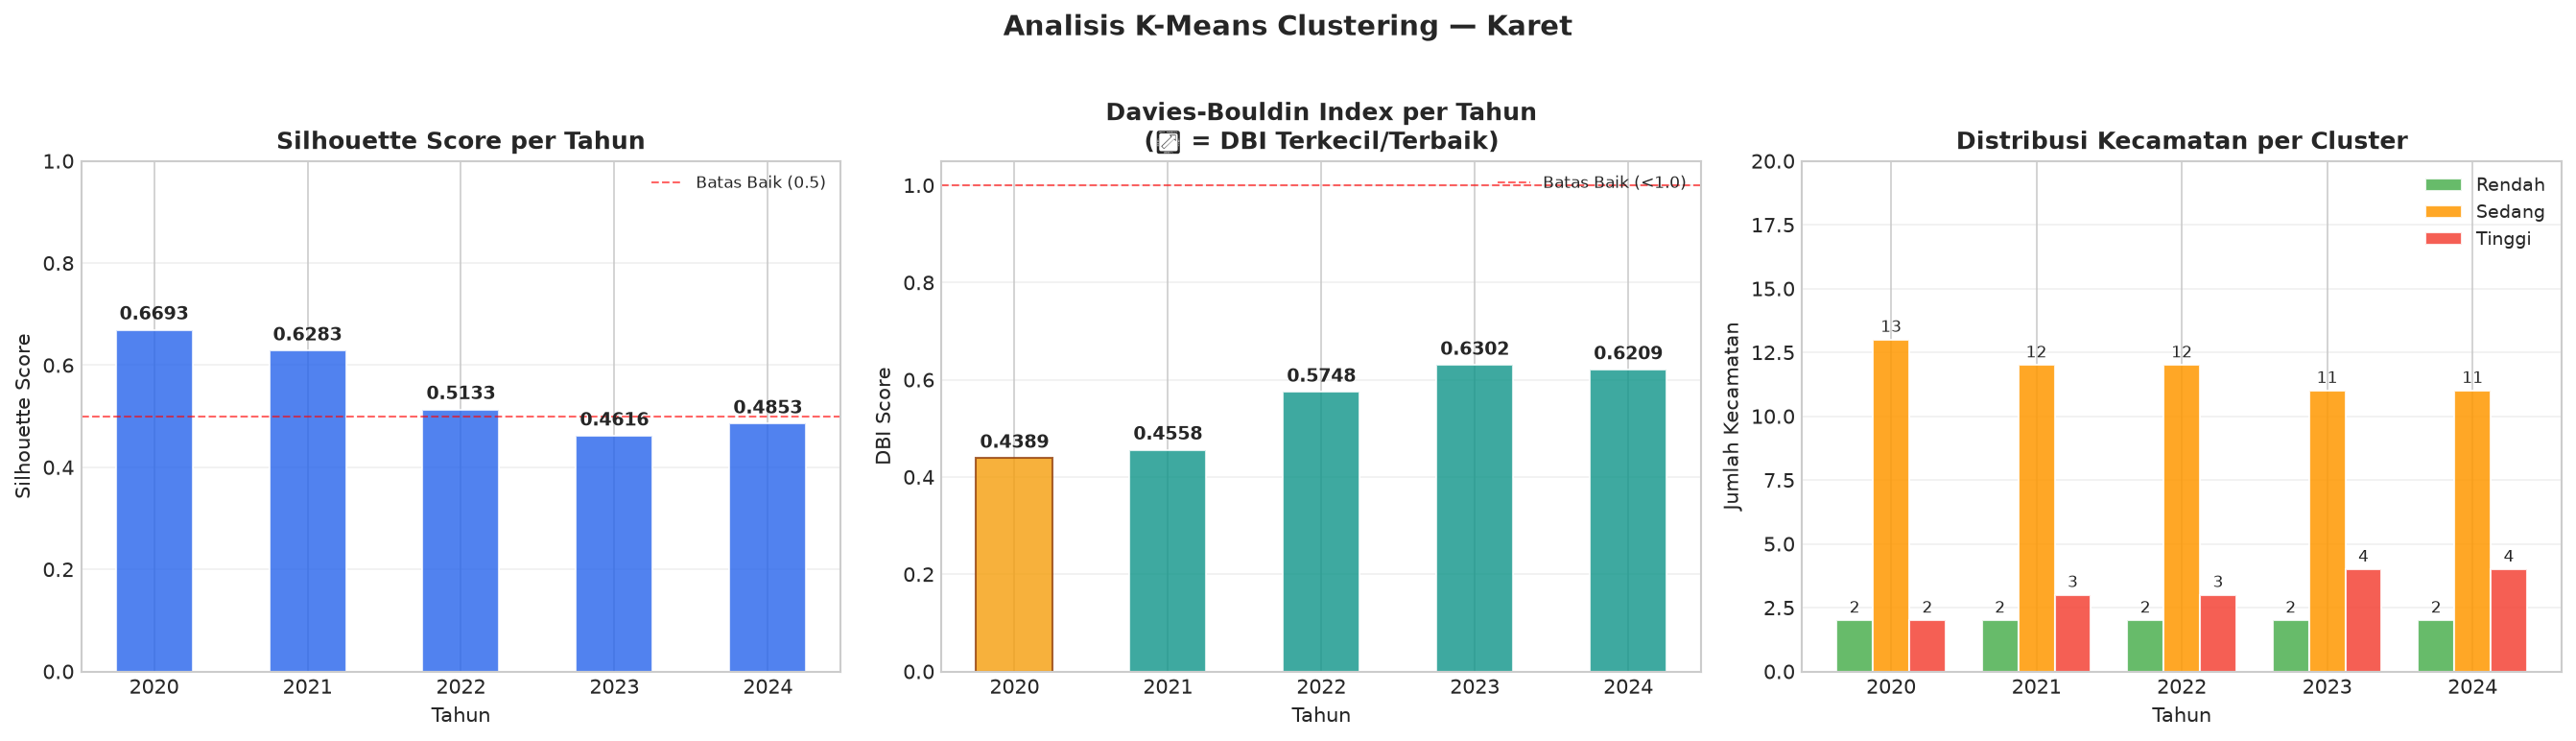

  ✅ Grafik evaluasi Karet disimpan → flask_app/static/images/charts/evaluasi_karet.png

📊 GRAFIK — KELAPA


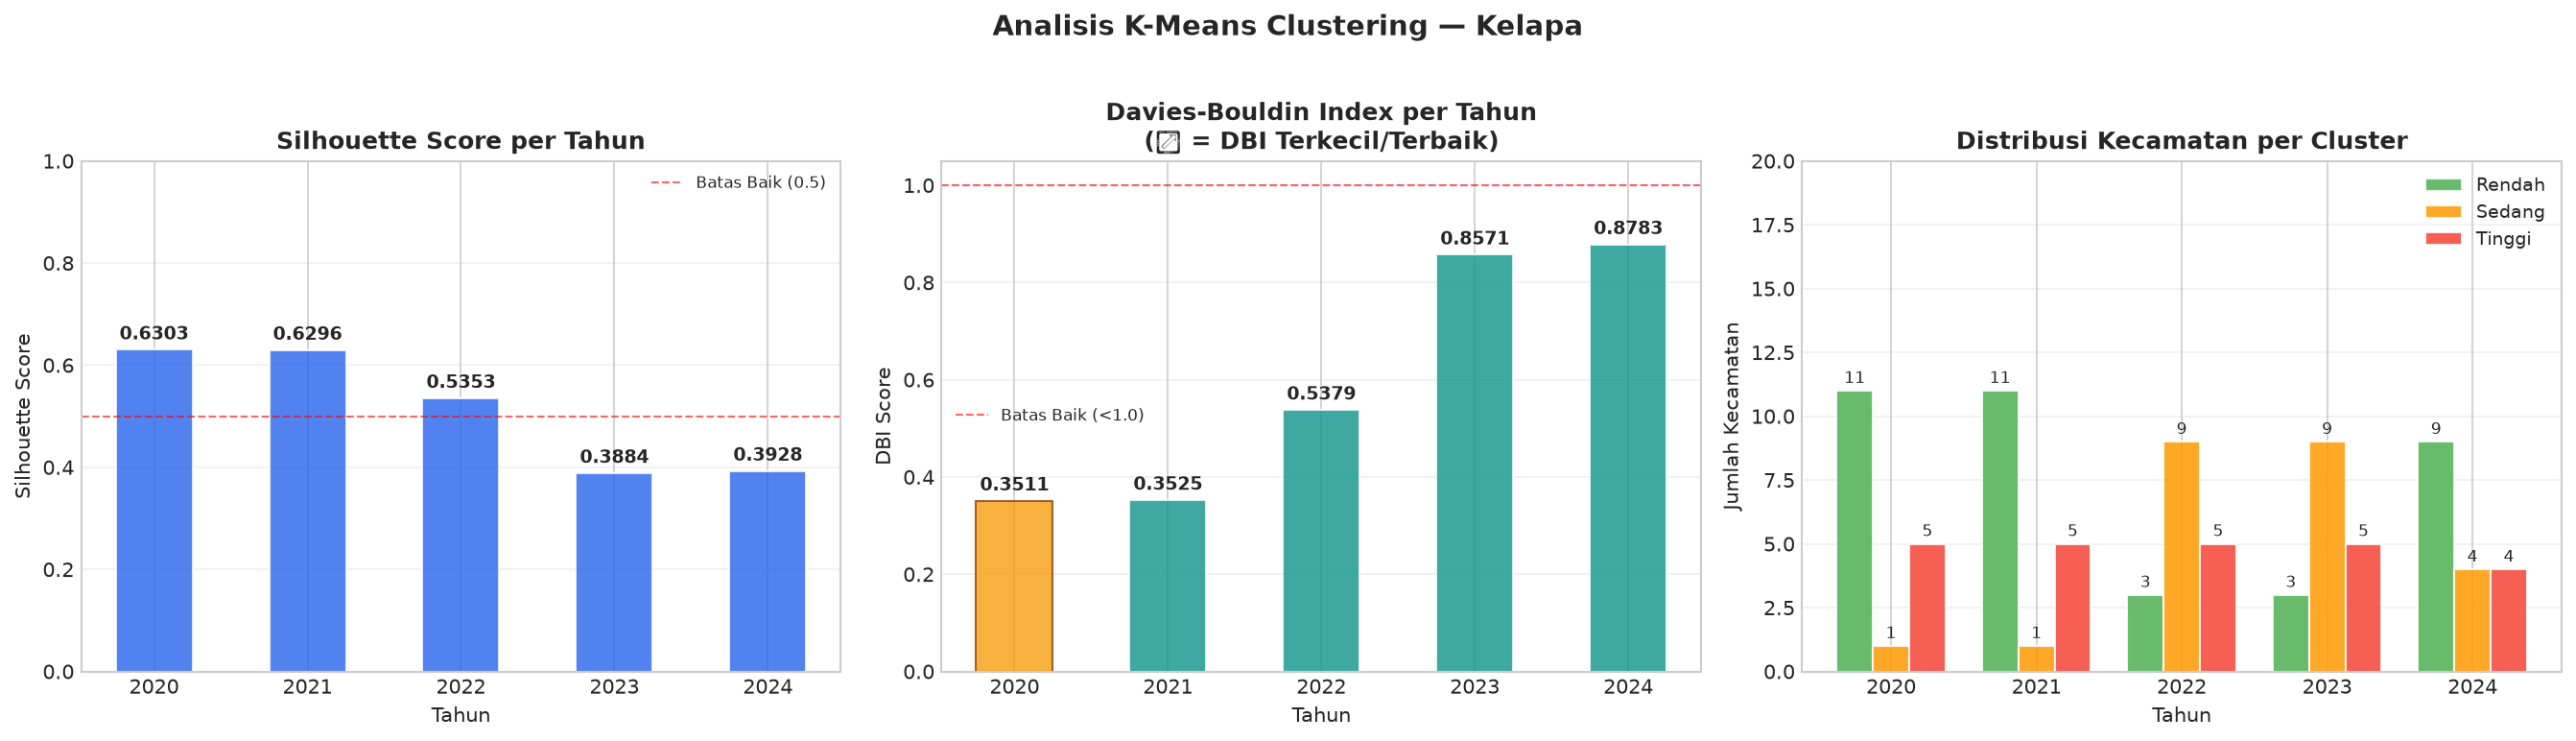

  ✅ Grafik evaluasi Kelapa disimpan → flask_app/static/images/charts/evaluasi_kelapa.png

📊 GRAFIK — PINANG


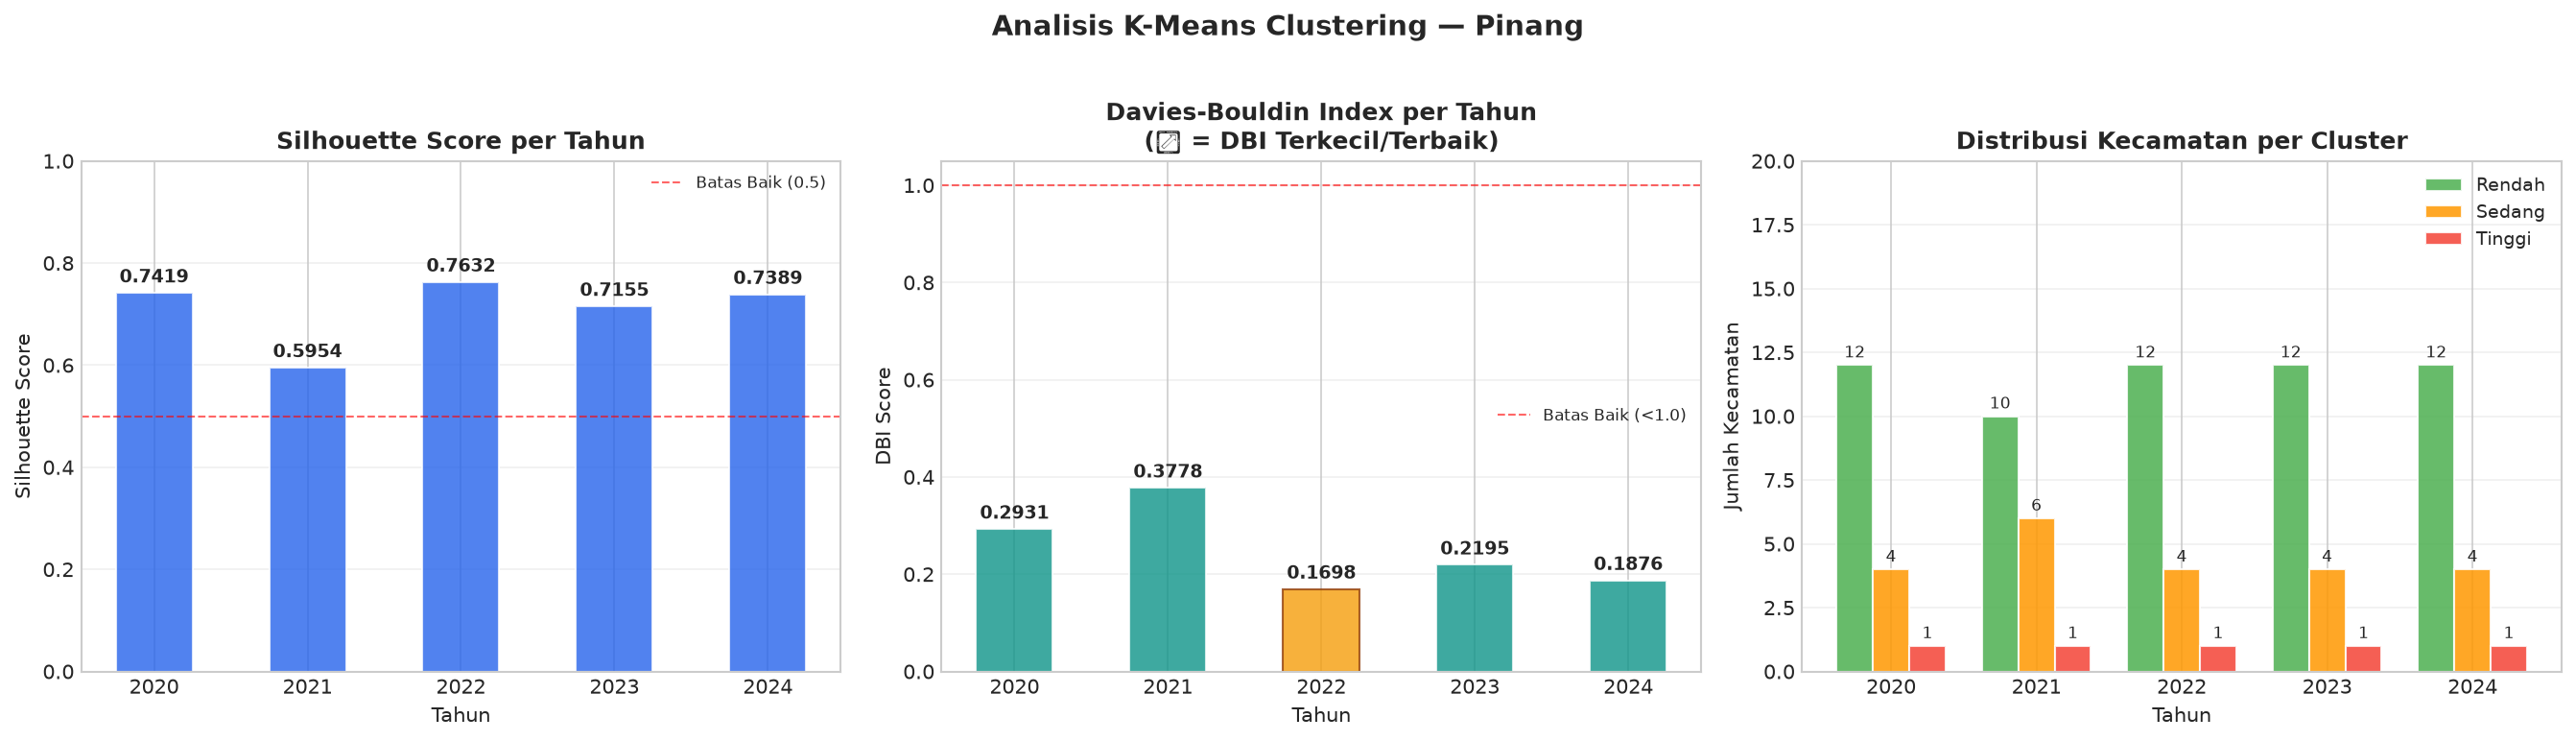

  ✅ Grafik evaluasi Pinang disimpan → flask_app/static/images/charts/evaluasi_pinang.png

✅ Semua grafik evaluasi berhasil dibuat dan disimpan


In [7]:
# ============================================================
# CELL 7: Visualisasi Grafik Evaluasi & Distribusi Cluster
# ============================================================

print('VISUALISASI GRAFIK EVALUASI & DISTRIBUSI CLUSTER')
print('=' * 55)

for komoditas in KOMODITAS_LIST:
    print(f'\n📊 GRAFIK — {komoditas.upper()}')

    # Kumpulkan data evaluasi per tahun
    sil_scores  = [all_results[komoditas][y]['silhouette_score'] for y in YEARS]
    dbi_scores  = [all_results[komoditas][y]['dbi_score']        for y in YEARS]
    dist_rendah = [get_cluster_summary(all_results[komoditas][y])[1] for y in YEARS]
    dist_sedang = [get_cluster_summary(all_results[komoditas][y])[2] for y in YEARS]
    dist_tinggi = [get_cluster_summary(all_results[komoditas][y])[3] for y in YEARS]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(
        f'Analisis K-Means Clustering — {komoditas}',
        fontsize=14, fontweight='bold', y=1.02
    )

    # ── Plot 1: Silhouette Score ──────────────────────────
    ax1 = axes[0]
    bars1 = ax1.bar(YEARS, sil_scores, color='#2563EB',
                    alpha=0.8, width=0.5, edgecolor='white')
    ax1.bar_label(bars1, labels=[f'{v:.4f}' for v in sil_scores],
                  padding=3, fontsize=9, fontweight='bold')
    ax1.axhline(y=0.5, color='red', linestyle='--',
                linewidth=1, alpha=0.6, label='Batas Baik (0.5)')
    ax1.set_title('Silhouette Score per Tahun', fontweight='bold')
    ax1.set_xlabel('Tahun')
    ax1.set_ylabel('Silhouette Score')
    ax1.set_ylim(0, 1)
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_xticks(YEARS)

    # ── Plot 2: DBI Score ─────────────────────────────────
    ax2 = axes[1]
    bars2 = ax2.bar(YEARS, dbi_scores, color='#0D9488',
                    alpha=0.8, width=0.5, edgecolor='white')
    ax2.bar_label(bars2, labels=[f'{v:.4f}' for v in dbi_scores],
                  padding=3, fontsize=9, fontweight='bold')
    ax2.axhline(y=1.0, color='red', linestyle='--',
                linewidth=1, alpha=0.6, label='Batas Baik (<1.0)')

    # Highlight tahun terbaik (DBI terkecil)
    best_idx = dbi_scores.index(min(dbi_scores))
    bars2[best_idx].set_color('#F59E0B')
    bars2[best_idx].set_edgecolor('#92400E')

    ax2.set_title('Davies-Bouldin Index per Tahun\n(⭐ = DBI Terkecil/Terbaik)',
                  fontweight='bold')
    ax2.set_xlabel('Tahun')
    ax2.set_ylabel('DBI Score')
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_xticks(YEARS)

    # ── Plot 3: Distribusi Cluster ────────────────────────
    ax3 = axes[2]
    x     = np.arange(len(YEARS))
    width = 0.25

    b1 = ax3.bar(x - width, dist_rendah, width, label='Rendah',
                 color='#4CAF50', alpha=0.85, edgecolor='white')
    b2 = ax3.bar(x,          dist_sedang, width, label='Sedang',
                 color='#FF9800', alpha=0.85, edgecolor='white')
    b3 = ax3.bar(x + width,  dist_tinggi, width, label='Tinggi',
                 color='#F44336', alpha=0.85, edgecolor='white')

    ax3.bar_label(b1, padding=2, fontsize=8)
    ax3.bar_label(b2, padding=2, fontsize=8)
    ax3.bar_label(b3, padding=2, fontsize=8)

    ax3.set_title('Distribusi Kecamatan per Cluster', fontweight='bold')
    ax3.set_xlabel('Tahun')
    ax3.set_ylabel('Jumlah Kecamatan')
    ax3.set_xticks(x)
    ax3.set_xticklabels(YEARS)
    ax3.legend(fontsize=9)
    ax3.grid(True, alpha=0.3, axis='y')
    ax3.set_ylim(0, 20)

    plt.tight_layout()
    save_path = (f'flask_app/static/images/charts/'
                 f'evaluasi_{komoditas.lower()}.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'  ✅ Grafik evaluasi {komoditas} disimpan → {save_path}')

print('\n✅ Semua grafik evaluasi berhasil dibuat dan disimpan')

In [8]:
# ============================================================
# CELL 8: Tabel Hasil Clustering Lengkap per Komoditas
# ============================================================

print('TABEL HASIL CLUSTERING LENGKAP')
print('=' * 55)

for komoditas in KOMODITAS_LIST:
    print(f'\n{"="*55}')
    print(f'  KOMODITAS: {komoditas.upper()}')
    print(f'{"="*55}')

    for tahun in YEARS:
        result = all_results[komoditas][tahun]
        dist   = get_cluster_summary(result)
        df_res = result['df_result'].copy()

        print(f'\n  Tahun {tahun} | '
              f'Silhouette: {result["silhouette_score"]} | '
              f'DBI: {result["dbi_score"]} | '
              f'Iterasi: {result["n_iter"]}')
        print(f'  Distribusi → Rendah: {dist[1]} | '
              f'Sedang: {dist[2]} | Tinggi: {dist[3]}')

        # Tabel per kecamatan
        tabel = df_res[[
            'Kecamatan', 'Produksi_Ton', 'Produktivitas_KgHa',
            'Cluster', 'Cluster_Nama'
        ]].sort_values(['Cluster', 'Produksi_Ton'],
                       ascending=[True, False])

        display(tabel.style
            .map(lambda v: f'background-color: '
                      f'{"#D1FAE5" if v == "Rendah" else "#FEF3C7" if v == "Sedang" else "#FEE2E2" if v == "Tinggi" else ""}',
                      subset=['Cluster_Nama'])
            .format({'Produksi_Ton': '{:.2f}',
                     'Produktivitas_KgHa': '{:.2f}'})
        )

# Tabel ringkasan evaluasi semua komoditas semua tahun
print('\n\nRINGKASAN EVALUASI SEMUA KOMODITAS')
print('=' * 55)

rows_eval = []
for komoditas in KOMODITAS_LIST:
    for tahun in YEARS:
        r    = all_results[komoditas][tahun]
        dist = get_cluster_summary(r)
        rows_eval.append({
            'Komoditas'        : komoditas,
            'Tahun'            : tahun,
            'Silhouette Score' : r['silhouette_score'],
            'DBI Score'        : r['dbi_score'],
            'Iterasi'          : r['n_iter'],
            'Inertia'          : r['inertia'],
            'Cluster Rendah'   : dist[1],
            'Cluster Sedang'   : dist[2],
            'Cluster Tinggi'   : dist[3],
        })

df_eval = pd.DataFrame(rows_eval)
display(df_eval)

# Simpan tabel evaluasi ke CSV
df_eval.to_csv('flask_app/static/data/evaluasi_clustering.csv', index=False)
print('\n✅ Tabel evaluasi disimpan ke Flask')

TABEL HASIL CLUSTERING LENGKAP

  KOMODITAS: KARET

  Tahun 2020 | Silhouette: 0.6693 | DBI: 0.4389 | Iterasi: 6
  Distribusi → Rendah: 2 | Sedang: 13 | Tinggi: 2


,Kecamatan,Produksi_Ton,Produktivitas_KgHa,Cluster,Cluster_Nama
16,Kutablang,34.60,400.00,1,Rendah
10,Jangka,8.10,630.00,1,Rendah
3,Jeunieb,123.50,900.00,2,Sedang
12,Peusangan Selatan,120.40,890.00,2,Sedang
7,Jeumpa,108.30,900.00,2,Sedang
13,Peusangan Siblah Krueng,98.80,950.00,2,Sedang
5,Peudada,79.00,875.00,2,Sedang
4,Peulimbang,69.60,890.00,2,Sedang
15,Gandapura,67.90,780.00,2,Sedang
14,Makmur,67.80,780.00,2,Sedang



  Tahun 2021 | Silhouette: 0.6283 | DBI: 0.4558 | Iterasi: 3
  Distribusi → Rendah: 2 | Sedang: 12 | Tinggi: 3


,Kecamatan,Produksi_Ton,Produktivitas_KgHa,Cluster,Cluster_Nama
16,Kutablang,35.76,435.00,1,Rendah
10,Jangka,12.34,600.00,1,Rendah
3,Jeunieb,137.95,890.00,2,Sedang
12,Peusangan Selatan,130.50,900.00,2,Sedang
4,Peulimbang,105.91,890.00,2,Sedang
5,Peudada,105.02,890.00,2,Sedang
14,Makmur,96.87,770.00,2,Sedang
0,Samalanga,78.76,895.00,2,Sedang
9,Kuala,75.67,780.00,2,Sedang
2,Pandrah,72.00,900.00,2,Sedang



  Tahun 2022 | Silhouette: 0.5133 | DBI: 0.5748 | Iterasi: 2
  Distribusi → Rendah: 2 | Sedang: 12 | Tinggi: 3


...


  Tahun 2024 | Silhouette: 0.7389 | DBI: 0.1876 | Iterasi: 3
  Distribusi → Rendah: 12 | Sedang: 4 | Tinggi: 1


,Kecamatan,Produksi_Ton,Produktivitas_KgHa,Cluster,Cluster_Nama
0,Samalanga,180.48,752.00,1,Rendah
11,Peusangan,162.75,775.00,1,Rendah
3,Jeunieb,152.25,750.00,1,Rendah
1,Simpang Mamplam,102.60,760.00,1,Rendah
4,Peulimbang,98.15,755.00,1,Rendah
10,Jangka,97.28,760.00,1,Rendah
5,Peudada,92.40,770.00,1,Rendah
16,Kutablang,85.12,760.00,1,Rendah
2,Pandrah,79.50,750.00,1,Rendah
15,Gandapura,78.75,750.00,1,Rendah




RINGKASAN EVALUASI SEMUA KOMODITAS


,Komoditas,Tahun,Silhouette Score,DBI Score,Iterasi,Inertia,Cluster Rendah,Cluster Sedang,Cluster Tinggi
0,Karet,2020,0.6693,0.4389,6,0.3178,2,13,2
1,Karet,2021,0.6283,0.4558,3,0.3616,2,12,3
2,Karet,2022,0.5133,0.5748,2,0.4641,2,12,3
3,Karet,2023,0.4616,0.6302,2,0.5157,2,11,4
4,Karet,2024,0.4853,0.6209,2,0.4717,2,11,4
5,Kelapa,2020,0.6303,0.3511,4,0.4282,11,1,5
6,Kelapa,2021,0.6296,0.3525,4,0.4288,11,1,5
7,Kelapa,2022,0.5353,0.5379,4,0.5641,3,9,5
8,Kelapa,2023,0.3884,0.8571,3,0.8248,3,9,5
9,Kelapa,2024,0.3928,0.8783,2,0.8627,9,4,4



✅ Tabel evaluasi disimpan ke Flask


In [9]:
# ============================================================
# CELL 9: Simpan Semua Output untuk Flask (JSON + Pickle)
# ============================================================

print('PERSIAPAN OUTPUT UNTUK FLASK')
print('=' * 55)

def convert_types(obj):
    """Konversi numpy types ke Python native untuk JSON"""
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, (np.integer,)):
        return int(obj)
    elif isinstance(obj, (np.floating,)):
        return float(obj)
    elif isinstance(obj, dict):
        return {k: convert_types(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [convert_types(i) for i in obj]
    return obj


# ── 1. Summary JSON per komoditas per tahun ───────────────
summary_json = {}

for komoditas in KOMODITAS_LIST:
    summary_json[komoditas] = {}
    for tahun in YEARS:
        r    = all_results[komoditas][tahun]
        dist = get_cluster_summary(r)

        # Data per kecamatan untuk web
        kec_data = []
        for i, kec in enumerate(r['kecamatan']):
            kec_data.append({
                'kecamatan'       : kec,
                'Produksi_Ton'    : r['data_asli'][i]['Produksi_Ton'],
                'Produktivitas'   : r['data_asli'][i]['Produktivitas_KgHa'],
                'cluster'         : r['labels_mapped'][i],
                'cluster_nama'    : r['cluster_nama'][i],
                'cluster_warna'   : CLUSTER_COLORS[r['labels_mapped'][i]],
                'jarak_centroid'  : [round(d, 4) for d in r['distances'][i]]
            })

        summary_json[komoditas][str(tahun)] = {
            'komoditas'        : komoditas,
            'tahun'            : tahun,
            'silhouette_score' : r['silhouette_score'],
            'dbi_score'        : r['dbi_score'],
            'n_iter'           : r['n_iter'],
            'inertia'          : r['inertia'],
            'distribusi'       : {
                'Rendah': dist[1],
                'Sedang': dist[2],
                'Tinggi': dist[3]
            },
            'kecamatan_data'   : kec_data,
            'centroids_asli'   : r['centroids_asli'],
            'vars_cluster'     : r['vars_cluster']
        }

# Konversi & simpan
summary_clean = convert_types(summary_json)
with open('flask_app/static/data/kmeans_summary.json', 'w') as f:
    json.dump(summary_clean, f, indent=2)
print('✅ kmeans_summary.json disimpan')

# ── 2. Evaluasi JSON ──────────────────────────────────────
eval_json = convert_types(df_eval.to_dict(orient='records'))
with open('flask_app/static/data/evaluasi_clustering.json', 'w') as f:
    json.dump(eval_json, f, indent=2)
print('✅ evaluasi_clustering.json disimpan')

# ── 3. Final summary ──────────────────────────────────────
final = {
    'project_info': {
        'judul'        : 'Pemetaan Geospasial Hasil Perkebunan di Kabupaten Bireuen',
        'metode'       : 'K-Means Clustering',
        'komoditas'    : KOMODITAS_LIST,
        'tahun'        : YEARS,
        'n_clusters'   : N_CLUSTERS,
        'vars_cluster' : CLUSTERING_VARS,
        'total_kec'    : int(df['Kecamatan'].nunique()),
        'total_records': len(df)
    },
    'best_clustering': {}
}

# Cari tahun terbaik (DBI terkecil) per komoditas
for komoditas in KOMODITAS_LIST:
    best_tahun = min(YEARS,
        key=lambda y: all_results[komoditas][y]['dbi_score'])
    final['best_clustering'][komoditas] = {
        'tahun'            : best_tahun,
        'silhouette_score' : all_results[komoditas][best_tahun]['silhouette_score'],
        'dbi_score'        : all_results[komoditas][best_tahun]['dbi_score'],
        'distribusi'       : get_cluster_summary(
                                all_results[komoditas][best_tahun])
    }

final_clean = convert_types(final)
with open('flask_app/static/data/final_results.json', 'w') as f:
    json.dump(final_clean, f, indent=2)
print('✅ final_results.json disimpan')

# ── 4. Pickle model lengkap ───────────────────────────────
# Hapus objek non-serializable sebelum pickle
all_results_pkl = {}
for komoditas in KOMODITAS_LIST:
    all_results_pkl[komoditas] = {}
    for tahun in YEARS:
        r = all_results[komoditas][tahun].copy()
        # Hapus df_result (bisa direkonstruksi)
        r.pop('df_result', None)
        r.pop('scaler', None)
        r.pop('kmeans_model', None)
        all_results_pkl[komoditas][tahun] = r

with open('flask_app/static/models/kmeans_results.pkl', 'wb') as f:
    pickle.dump({
        'all_results'  : all_results_pkl,
        'summary'      : summary_clean,
        'evaluasi'     : eval_json,
        'final'        : final_clean,
        'KOMODITAS_LIST': KOMODITAS_LIST,
        'YEARS'        : YEARS,
        'N_CLUSTERS'   : N_CLUSTERS,
        'CLUSTER_NAMES': CLUSTER_NAMES,
        'CLUSTER_COLORS': CLUSTER_COLORS,
        'CLUSTERING_VARS': CLUSTERING_VARS
    }, f)
print('✅ kmeans_results.pkl disimpan')

# Tampilkan semua file output
print('\n📁 FILE OUTPUT FLASK:')
for root, dirs, files in os.walk('flask_app/static'):
    for file in files:
        path = os.path.join(root, file)
        size = os.path.getsize(path)
        print(f'   {path} ({size:,} bytes)')

PERSIAPAN OUTPUT UNTUK FLASK
✅ kmeans_summary.json disimpan
✅ evaluasi_clustering.json disimpan
✅ final_results.json disimpan
✅ kmeans_results.pkl disimpan

📁 FILE OUTPUT FLASK:
   flask_app/static/images/charts/evaluasi_karet.png (112,737 bytes)
   flask_app/static/images/charts/evaluasi_kelapa.png (111,592 bytes)
   flask_app/static/images/charts/evaluasi_pinang.png (111,316 bytes)
   flask_app/static/models/kmeans_results.pkl (57,380 bytes)
   flask_app/static/data/perkebunan_bireuen_original.csv (8,924 bytes)
   flask_app/static/data/evaluasi_clustering.json (3,414 bytes)
   flask_app/static/data/kmeans_summary.json (91,964 bytes)
   flask_app/static/data/evaluasi_clustering.csv (726 bytes)
   flask_app/static/data/final_results.json (1,010 bytes)


In [10]:
# ============================================================
# CELL 10: Ringkasan & Kesimpulan
# ============================================================

print('RINGKASAN K-MEANS CLUSTERING PERKEBUNAN BIREUEN')
print('=' * 55)

print(f'\n📊 STATISTIK DATASET')
print(f'  Total record    : {len(df)} baris')
print(f'  Komoditas       : {", ".join(KOMODITAS_LIST)}')
print(f'  Periode         : {min(YEARS)} – {max(YEARS)}')
print(f'  Jumlah kecamatan: {df["Kecamatan"].nunique()}')
print(f'  Variabel        : {", ".join(CLUSTERING_VARS)}')

print(f'\n🎯 HASIL K-MEANS CLUSTERING')

for komoditas in KOMODITAS_LIST:
    print(f'\n  {"─"*50}')
    print(f'  {komoditas.upper()}')
    print(f'  {"─"*50}')

    sil_list = [all_results[komoditas][y]['silhouette_score'] for y in YEARS]
    dbi_list = [all_results[komoditas][y]['dbi_score']        for y in YEARS]

    best_y_dbi = YEARS[dbi_list.index(min(dbi_list))]
    best_y_sil = YEARS[sil_list.index(max(sil_list))]

    for tahun in YEARS:
        r    = all_results[komoditas][tahun]
        dist = get_cluster_summary(r)
        flag = ' ⭐' if tahun == best_y_dbi else ''
        print(f'  {tahun}{flag}: '
              f'Sil={r["silhouette_score"]:.4f} | '
              f'DBI={r["dbi_score"]:.4f} | '
              f'R={dist[1]} S={dist[2]} T={dist[3]}')

    print(f'\n  ➜ Tahun terbaik (DBI terkecil) : {best_y_dbi}')
    print(f'  ➜ Tahun terbaik (Sil terbesar) : {best_y_sil}')

print(f'\n\n🏆 RINGKASAN TERBAIK PER KOMODITAS')
print('-' * 55)

df_best = pd.DataFrame([{
    'Komoditas'        : k,
    'Tahun Terbaik'    : final_clean['best_clustering'][k]['tahun'],
    'Silhouette Score' : final_clean['best_clustering'][k]['silhouette_score'],
    'DBI Score'        : final_clean['best_clustering'][k]['dbi_score'],
    'Rendah'           : final_clean['best_clustering'][k]['distribusi'][1],
    'Sedang'           : final_clean['best_clustering'][k]['distribusi'][2],
    'Tinggi'           : final_clean['best_clustering'][k]['distribusi'][3],
} for k in KOMODITAS_LIST])

display(df_best)

print(f'\n💡 REKOMENDASI')
print('-' * 55)
for komoditas in KOMODITAS_LIST:
    best = final_clean['best_clustering'][komoditas]
    dist = best['distribusi']
    print(f'\n  {komoditas}:')
    print(f'  • {dist[3]} kecamatan produksi Tinggi → pertahankan & replikasi')
    print(f'  • {dist[2]} kecamatan produksi Sedang → intensifikasi')
    print(f'  • {dist[1]} kecamatan produksi Rendah → perlu perhatian khusus')

print(f'\n\n✅ NOTEBOOK SELESAI — SIAP IMPLEMENTASI KE FLASK')
print(f'✅ Semua file output tersimpan di flask_app/static/')
print(f'\n🚀 NEXT STEPS:')
print('  1. Update app.py → load kmeans_summary.json')
print('  2. Update dashboard → tampilkan hasil clustering')
print('  3. Update halaman hasil analisis → peta + tabel + grafik')

RINGKASAN K-MEANS CLUSTERING PERKEBUNAN BIREUEN

📊 STATISTIK DATASET
  Total record    : 255 baris
  Komoditas       : Karet, Kelapa, Pinang
  Periode         : 2020 – 2024
  Jumlah kecamatan: 17
  Variabel        : Produksi_Ton, Produktivitas_KgHa

🎯 HASIL K-MEANS CLUSTERING

  ──────────────────────────────────────────────────
  KARET
  ──────────────────────────────────────────────────
  2020 ⭐: Sil=0.6693 | DBI=0.4389 | R=2 S=13 T=2
  2021: Sil=0.6283 | DBI=0.4558 | R=2 S=12 T=3
  2022: Sil=0.5133 | DBI=0.5748 | R=2 S=12 T=3
  2023: Sil=0.4616 | DBI=0.6302 | R=2 S=11 T=4
  2024: Sil=0.4853 | DBI=0.6209 | R=2 S=11 T=4

  ➜ Tahun terbaik (DBI terkecil) : 2020
  ➜ Tahun terbaik (Sil terbesar) : 2020

  ──────────────────────────────────────────────────
  KELAPA
  ──────────────────────────────────────────────────
  2020 ⭐: Sil=0.6303 | DBI=0.3511 | R=11 S=1 T=5
  2021: Sil=0.6296 | DBI=0.3525 | R=11 S=1 T=5
  2022: Sil=0.5353 | DBI=0.5379 | R=3 S=9 T=5
  2023: Sil=0.3884 | DBI=0.8571 

,Komoditas,Tahun Terbaik,Silhouette Score,DBI Score,Rendah,Sedang,Tinggi
0,Karet,2020,0.6693,0.4389,2,13,2
1,Kelapa,2020,0.6303,0.3511,11,1,5
2,Pinang,2022,0.7632,0.1698,12,4,1



💡 REKOMENDASI
-------------------------------------------------------

  Karet:
  • 2 kecamatan produksi Tinggi → pertahankan & replikasi
  • 13 kecamatan produksi Sedang → intensifikasi
  • 2 kecamatan produksi Rendah → perlu perhatian khusus

  Kelapa:
  • 5 kecamatan produksi Tinggi → pertahankan & replikasi
  • 1 kecamatan produksi Sedang → intensifikasi
  • 11 kecamatan produksi Rendah → perlu perhatian khusus

  Pinang:
  • 1 kecamatan produksi Tinggi → pertahankan & replikasi
  • 4 kecamatan produksi Sedang → intensifikasi
  • 12 kecamatan produksi Rendah → perlu perhatian khusus


✅ NOTEBOOK SELESAI — SIAP IMPLEMENTASI KE FLASK
✅ Semua file output tersimpan di flask_app/static/

🚀 NEXT STEPS:
  1. Update app.py → load kmeans_summary.json
  2. Update dashboard → tampilkan hasil clustering
  3. Update halaman hasil analisis → peta + tabel + grafik
